# Spaceship Titanic — Comparaison systématique des techniques de Machine Learning

**Objectif :** prédire si un passager a été « transporté » dans une autre dimension (classification binaire, métrique = accuracy).

**Principe du projet : ne rien supposer, tout mesurer.** Chaque technique (feature engineering, imputation, encodage, normalisation, PCA, sélection de features, modèles, tuning, ensembles) est testée **une par une**, avec le même protocole de validation croisée, et on ne garde que ce qui améliore réellement le score.

| Phase | Contenu |
|---|---|
| 0 | Exploration des données |
| 1 | Baselines |
| 2 | Feature engineering |
| 3 | Imputation des valeurs manquantes |
| 4 | Encodage des variables catégorielles |
| 5 | Normalisation |
| 6 | PCA et sélection de features |
| 7 | Comparaison de 13 modèles |
| 8 | Tuning des hyperparamètres avec Optuna |
| 9 | Ensembles |
| 10 | Solution finale et soumission |
| 11 | Features v2, stacking avec TabPFN, seuil de décision |

## Google Colab / Kaggle

Cette cellule installe les bibliothèques absentes (en local, elle ne fait rien). Le GPU est utile pour TabPFN (phase 11).

- **Colab** : *Exécution → Modifier le type d'exécution → GPU T4* ; mettre `train.csv` et `test.csv` dans un dossier `data/`.
- **Kaggle** : *Settings → Accelerator → GPU* et *Settings → Internet → On* (nécessaire pour `pip` et pour télécharger TabPFN) ; ajouter les données de la compétition avec *Add Input*. Le dossier des données est trouvé automatiquement.
- **TabPFN** : ses poids sont soumis à une licence. L'accepter une fois sur https://ux.priorlabs.ai (onglet *Licenses*), copier la clé API (page *Account*), puis l'enregistrer comme secret nommé `TABPFN_TOKEN` (Kaggle : *Add-ons → Secrets* ; Colab : icône 🔑). Ne jamais écrire la clé en clair dans le notebook.

In [ ]:
import os
import sys

if "google.colab" in sys.modules:
    !pip install -q catboost optuna tabpfn
elif os.path.exists("/kaggle/input"):
    !pip install -q tabpfn  # le reste est déjà installé sur Kaggle

# Clé API TabPFN (licence à accepter une fois sur https://ux.priorlabs.ai), stockée en secret « TABPFN_TOKEN »
try:
    if "google.colab" in sys.modules:
        from google.colab import userdata
        os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")
    elif os.path.exists("/kaggle/input"):
        from kaggle_secrets import UserSecretsClient
        os.environ["TABPFN_TOKEN"] = UserSecretsClient().get_secret("TABPFN_TOKEN")
except Exception as e:  # pas de secret : TabPFN demandera la licence au premier fit
    print(f"Secret TABPFN_TOKEN introuvable ({type(e).__name__}) : TabPFN ne pourra pas télécharger ses poids")

## Mise en place

### Imports et constantes

In [1]:
import os
import time
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"  # transmis aux processus de la validation croisée
warnings.filterwarnings("ignore")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import RFECV, SelectFromModel
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder,
    PowerTransformer,
    QuantileTransformer,
    RobustScaler,
    StandardScaler,
    TargetEncoder,
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

T0 = time.time()
SEED = 42
N_THREADS = os.cpu_count() or 4
N_JOBS = min(4, N_THREADS)  # processus parallèles (chacun a sa copie des données) : à baisser si la mémoire manque

KAGGLE_INPUT = Path("/kaggle/input")  # sur Kaggle : on cherche train.csv parmi les données ajoutées au notebook
DATA_DIR = next((p.parent for p in KAGGLE_INPUT.rglob("train.csv")), Path("data")) if KAGGLE_INPUT.exists() else Path("data")
RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"
SUB_DIR = Path("submissions")
for d in (RESULTS_DIR, FIG_DIR, SUB_DIR):
    d.mkdir(parents=True, exist_ok=True)

### Style des graphiques

Une seule palette pour tout le notebook : bleu = série principale, orange = série de comparaison. Grille et axes discrets, pour que l'œil aille aux données.

In [2]:
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
CMAP_BLUE = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#3987e5", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "lines.linewidth": 2,
})


def savefig(fig, name):
    """Enregistre la figure dans results/figures/ puis l'affiche."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def pct(x, digits=2):
    return f"{100 * x:.{digits}f} %"

### Chargement des données

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

y = train["Transported"].astype(int).to_numpy()
n_train = len(train)

# Train et test empilés : sert uniquement à construire des features qui n'utilisent PAS la cible
full = pd.concat([train.drop(columns="Transported"), test], ignore_index=True)

print(f"train : {train.shape[0]} passagers, {train.shape[1]} colonnes")
print(f"test  : {test.shape[0]} passagers, {test.shape[1]} colonnes")
train.head()

train : 8693 passagers, 14 colonnes
test  : 4277 passagers, 13 colonnes


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### Le protocole de validation

Toutes les expériences du notebook passent par la fonction `run` ci-dessous. Elle applique les règles du projet :

1. **Validation croisée 5 folds × 3 répétitions** : 15 scores par expérience, résumés par *moyenne ± écart-type*.
2. **Les mêmes folds pour toutes les expériences** : les découpages sont calculés une seule fois (`SPLITS`) et réutilisés partout. Deux expériences sont donc comparables fold par fold.
3. **Aucune fuite de données** : ce qu'on évalue est toujours un `Pipeline` scikit-learn complet (imputation → encodage → normalisation → modèle). Il est ré-entraîné de zéro dans chaque fold, uniquement sur la partie entraînement.
4. **Un seul changement à la fois**, comparé à une expérience de référence.

**Comment décide-t-on qu'un changement est une amélioration ?** Comme les folds sont identiques, on compare deux expériences fold par fold (comparaison *appariée*) :

- **gain** = moyenne des 15 différences de score ;
- **folds gagnés** = nombre de folds (sur 15) où la nouvelle version est meilleure.

| Verdict | Condition | Décision |
|---|---|---|
| amélioration nette | gain > écart-type de la référence | adopté |
| gain faible mais régulier | gain > 0 et au moins 10 folds gagnés sur 15 | adopté |
| dans le bruit | ni gain ni perte régulière | rejeté (on garde le plus simple) |
| perte faible mais régulière | perte et au moins 10 folds perdus sur 15 | rejeté |
| dégradation nette | perte > écart-type de la référence | rejeté |

Ce n'est pas un test statistique rigoureux (les folds d'une validation croisée répétée ne sont pas indépendants), mais c'est un filtre simple qui évite d'adopter un « progrès » de 0,1 % obtenu par chance.

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
SPLITS = list(cv.split(np.zeros(n_train), y))  # figés une fois pour toutes
N_SPLITS, N_REPEATS = 5, 3
MIN_WINS = 10

EXPERIMENTS = []  # une ligne par expérience -> results/experiments.csv
SCORES = {}       # nom de l'expérience -> les 15 scores


def compare(new, ref):
    """Comparaison appariée de deux expériences (mêmes folds)."""
    diff = SCORES[new] - SCORES[ref]
    gain, wins, losses, std_ref = diff.mean(), int((diff > 0).sum()), int((diff < 0).sum()), SCORES[ref].std()
    if gain > std_ref:
        verdict = "amélioration nette"
    elif gain > 0 and wins >= MIN_WINS:
        verdict = "gain faible mais régulier"
    elif gain < -std_ref:
        verdict = "dégradation nette"
    elif gain < 0 and losses >= MIN_WINS:
        verdict = "perte faible mais régulière"
    else:
        verdict = "dans le bruit"
    adopted = verdict in ("amélioration nette", "gain faible mais régulier")
    return dict(gain=gain, wins=wins, verdict=verdict, adopted=adopted)


def log_experiment(phase, name, scores, ref=None, seconds=0.0, n_features=None, note=""):
    """Ajoute une expérience au journal et l'affiche sur une ligne."""
    key = f"P{phase} · {name}"
    SCORES[key] = np.asarray(scores)
    row = dict(phase=phase, experiment=name, accuracy_mean=SCORES[key].mean(), accuracy_std=SCORES[key].std(),
               reference=ref, gain=np.nan, folds_won=np.nan, verdict="", n_features=n_features,
               seconds=round(seconds, 1), note=note)
    line = f"{name:<52} {row['accuracy_mean']:.4f} ± {row['accuracy_std']:.4f}"
    if ref is not None:
        c = compare(key, ref)
        row.update(gain=c["gain"], folds_won=c["wins"], verdict=c["verdict"])
        line += f" | gain {c['gain']:+.4f} ({c['wins']:>2}/15 folds) -> {c['verdict']}"
    print(line)
    EXPERIMENTS.append(row)
    pd.DataFrame(EXPERIMENTS).to_csv(RESULTS_DIR / "experiments.csv", index=False)
    return key


def run(phase, name, pipe, X, ref=None, note="", n_jobs=N_JOBS):
    """Évalue un pipeline avec le protocole commun et l'enregistre dans le journal."""
    t = time.time()
    scores = cross_val_score(pipe, X, y, cv=SPLITS, scoring="accuracy", n_jobs=n_jobs)
    return log_experiment(phase, name, scores, ref=ref, seconds=time.time() - t, n_features=X.shape[1], note=note)


def best_adopted(candidates, ref):
    """Parmi des expériences candidates, renvoie la meilleure qui passe la règle de décision (ou None)."""
    ok = [k for k in candidates if compare(k, ref)["adopted"]]
    return max(ok, key=lambda k: SCORES[k].mean()) if ok else None


def show_phase(phase):
    """Tableau récapitulatif des expériences d'une phase."""
    df = pd.DataFrame(EXPERIMENTS)
    df = df[df["phase"] == phase].copy()
    df["accuracy CV"] = df["accuracy_mean"].map("{:.4f}".format) + " ± " + df["accuracy_std"].map("{:.4f}".format)
    df["gain"] = df["gain"].map(lambda g: "" if pd.isna(g) else f"{g:+.4f}")
    df["folds gagnés"] = df["folds_won"].map(lambda w: "" if pd.isna(w) else f"{int(w)}/15")
    display(df[["experiment", "accuracy CV", "gain", "folds gagnés", "verdict"]].reset_index(drop=True))


PROGRESS = []  # (étape, clé de l'expérience retenue à cette étape) -> tableau de progression final


def mean_std(key):
    return f"{SCORES[key].mean():.4f} ± {SCORES[key].std():.4f}"

---
## Phase 0 — Exploration des données

Avant de modéliser, on regarde les données : la cible est-elle équilibrée ? Combien de valeurs manquent ? Quelles colonnes semblent liées à la cible ?

In [5]:
SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

print(f"Taux de passagers transportés : {pct(y.mean())}  -> classes équilibrées, l'accuracy est une métrique fiable\n")
train.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]]

Taux de passagers transportés : 50.36 %  -> classes équilibrées, l'accuracy est une métrique fiable



,count,unique,top,mean,min,max
PassengerId,8693,8693,0001_01,NaN,NaN,NaN
HomePlanet,8492,3,Earth,NaN,NaN,NaN
CryoSleep,8476,2,False,NaN,NaN,NaN
Cabin,8494,6560,G/734/S,NaN,NaN,NaN
Destination,8511,3,TRAPPIST-1e,NaN,NaN,NaN
Age,8514.0,NaN,NaN,28.82793,0.0,79.0
VIP,8490,2,False,NaN,NaN,NaN
RoomService,8512.0,NaN,NaN,224.687617,0.0,14327.0
FoodCourt,8510.0,NaN,NaN,458.077203,0.0,29813.0
ShoppingMall,8485.0,NaN,NaN,173.729169,0.0,23492.0


### Valeurs manquantes

Lignes avec au moins une valeur manquante : 24.0 %


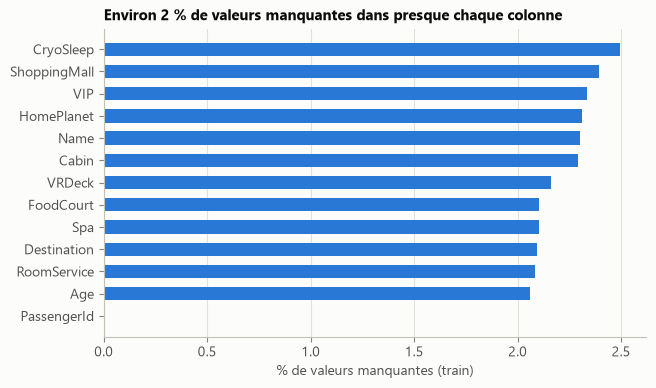

In [6]:
missing = (train.drop(columns="Transported").isna().mean() * 100).sort_values()
print(f"Lignes avec au moins une valeur manquante : {pct(train.isna().any(axis=1).mean(), 1)}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(missing.index, missing.values, height=0.6, color=C_BLUE)
ax.set_xlabel("% de valeurs manquantes (train)")
ax.set_title("Environ 2 % de valeurs manquantes dans presque chaque colonne")
ax.grid(axis="y", visible=False)
savefig(fig, "01_valeurs_manquantes")

### Variables catégorielles et cible

Pour chaque catégorie, on trace le **taux de passagers transportés**. La ligne grise est le taux moyen (≈ 50 %) : plus une barre s'en éloigne, plus la variable est informative.

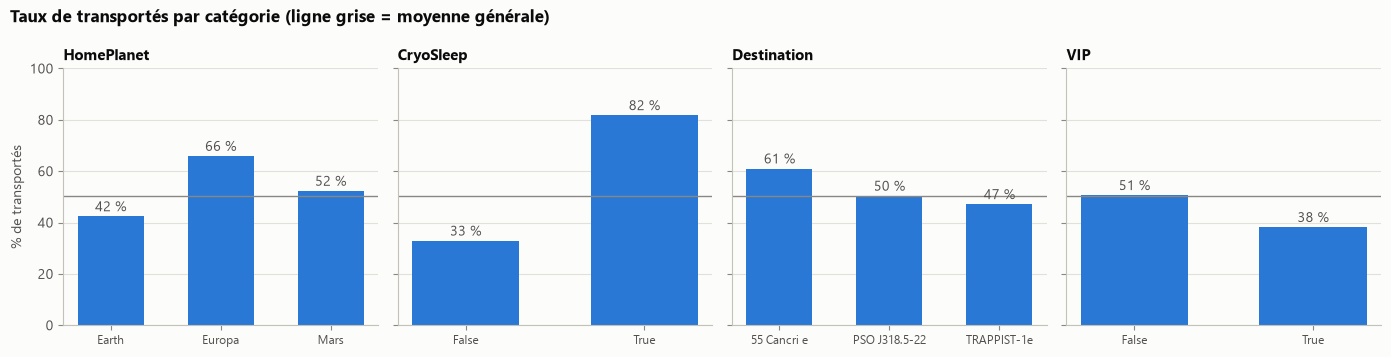

In [7]:
def rate_bars(ax, series, title, order=None):
    """Barres du taux de transportés par modalité d'une variable."""
    rates = pd.Series(y, index=series.index).groupby(series).mean() * 100
    if order is not None:
        rates = rates.reindex(order)
    labels = [str(i) for i in rates.index]
    ax.bar(labels, rates.values, width=0.6, color=C_BLUE)
    ax.axhline(y.mean() * 100, color=MUTED, linewidth=1)
    ax.set_title(title)
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
    if len(rates) <= 4:  # peu de barres : on peut afficher la valeur
        for i, v in enumerate(rates.values):
            ax.text(i, v + 2, f"{v:.0f} %", ha="center", color=INK_2)
    return rates


fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, col in zip(axes, ["HomePlanet", "CryoSleep", "Destination", "VIP"]):
    rate_bars(ax, train[col], col)
    ax.tick_params(axis="x", labelsize=8.5)
axes[0].set_ylabel("% de transportés")
fig.suptitle("Taux de transportés par catégorie (ligne grise = moyenne générale)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "02_taux_par_categorie")

### Âge

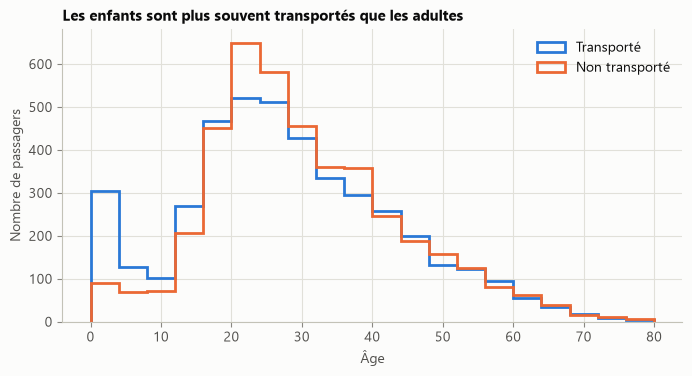

Taux de transportés — 12 ans et moins : 70.0 % | plus de 12 ans : 48.3 %
Dépense maximale d'un passager de 12 ans ou moins (train + test) : 0


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0, 81, 4)
for label, mask, color in [("Transporté", y == 1, C_BLUE), ("Non transporté", y == 0, C_ORANGE)]:
    ax.hist(train.loc[mask, "Age"].dropna(), bins=bins, histtype="step", linewidth=2, color=color, label=label)
ax.set_xlabel("Âge")
ax.set_ylabel("Nombre de passagers")
ax.set_title("Les enfants sont plus souvent transportés que les adultes")
ax.legend()
savefig(fig, "03_age")

children = (train["Age"] <= 12).to_numpy()
adults = (train["Age"] > 12).to_numpy()
print(f"Taux de transportés — 12 ans et moins : {pct(y[children].mean(), 1)} | plus de 12 ans : {pct(y[adults].mean(), 1)}")
print(f"Dépense maximale d'un passager de 12 ans ou moins (train + test) : {full.loc[full['Age'] <= 12, SPEND].max().max():.0f}")

### Dépenses à bord

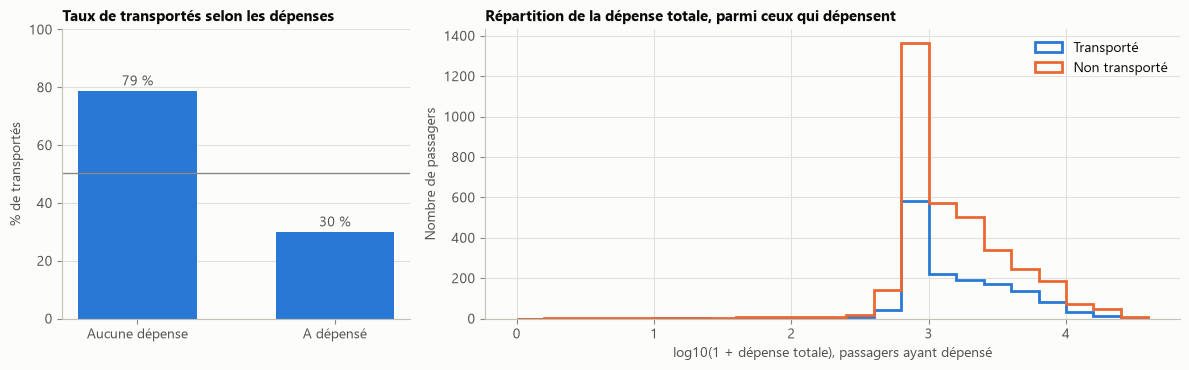

Dépense maximale d'un passager en cryosommeil (train + test) : 0
Taux de transportés selon qu'on a dépensé ou non dans chaque service :


,dépense > 0,dépense = 0
RoomService,26.0 %,63.3 %
FoodCourt,34.5 %,59.1 %
ShoppingMall,31.7 %,59.9 %
Spa,27.7 %,63.9 %
VRDeck,27.5 %,62.8 %


In [9]:
total = train[SPEND].sum(axis=1)
no_spend = total == 0

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
rate_bars(axes[0], no_spend.map({True: "Aucune dépense", False: "A dépensé"}), "Taux de transportés selon les dépenses",
          order=["Aucune dépense", "A dépensé"])
axes[0].set_ylabel("% de transportés")

bins = np.linspace(0, 4.6, 24)
for label, mask, color in [("Transporté", y == 1, C_BLUE), ("Non transporté", y == 0, C_ORANGE)]:
    axes[1].hist(np.log10(1 + total[mask & ~no_spend.to_numpy()]), bins=bins, histtype="step", linewidth=2, color=color, label=label)
axes[1].set_xlabel("log10(1 + dépense totale), passagers ayant dépensé")
axes[1].set_ylabel("Nombre de passagers")
axes[1].set_title("Répartition de la dépense totale, parmi ceux qui dépensent")
axes[1].legend()
fig.tight_layout()
savefig(fig, "04_depenses")

cryo = full["CryoSleep"] == True  # noqa: E712
print(f"Dépense maximale d'un passager en cryosommeil (train + test) : {full.loc[cryo, SPEND].max().max():.0f}")
print("Taux de transportés selon qu'on a dépensé ou non dans chaque service :")
display(pd.DataFrame({
    s: {"dépense > 0": y[(train[s] > 0).to_numpy()].mean(), "dépense = 0": y[(train[s] == 0).to_numpy()].mean()} for s in SPEND
}).T.map(lambda v: pct(v, 1)))

### Cabine et groupes

`Cabin` a la forme `pont/numéro/côté` et `PassengerId` la forme `groupe_numéro`. On les découpe pour voir si la position dans le vaisseau et la taille du groupe comptent.

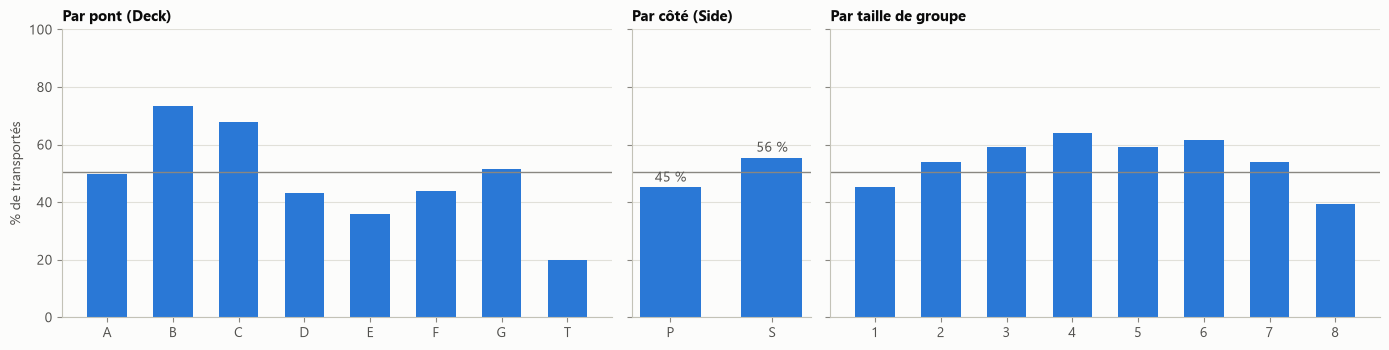

Passagers voyageant en groupe (taille > 1) : 44.7 %
Groupes de 2+ dont tous les membres ont le même sort : 43.6 %
Groupes de 2+ avec plusieurs planètes d'origine (train + test) : 0
Groupes présents à la fois dans le train et dans le test : 0


In [10]:
cabin = train["Cabin"].str.split("/", expand=True)
group = train["PassengerId"].str[:4]
group_size = group.map(group.value_counts())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True, gridspec_kw={"width_ratios": [4, 1.3, 4]})
rate_bars(axes[0], cabin[0], "Par pont (Deck)")
rate_bars(axes[1], cabin[2], "Par côté (Side)")
rate_bars(axes[2], group_size, "Par taille de groupe")
axes[0].set_ylabel("% de transportés")
fig.tight_layout()
savefig(fig, "05_cabine_groupe")

full_group = full["PassengerId"].str[:4]
by_group = pd.Series(y).groupby(group.to_numpy())
same_fate = by_group.nunique()[by_group.size() > 1] == 1
print(f"Passagers voyageant en groupe (taille > 1) : {pct((group_size > 1).mean(), 1)}")
print(f"Groupes de 2+ dont tous les membres ont le même sort : {pct(same_fate.mean(), 1)}")
print(f"Groupes de 2+ avec plusieurs planètes d'origine (train + test) : {(full.groupby(full_group)['HomePlanet'].nunique() > 1).sum()}")
print(f"Groupes présents à la fois dans le train et dans le test : {len(set(group) & set(test['PassengerId'].str[:4]))}")

**Ce que montre l'exploration**

- **Cible équilibrée** : 50,4 % de transportés. L'accuracy est donc une métrique adaptée, et le plancher (toujours prédire la même classe) est d'environ 50 %.
- **Valeurs manquantes** : environ 2 % par colonne, mais réparties sur des lignes différentes : **24 % des passagers** ont au moins une valeur manquante. Supprimer ces lignes ferait perdre un quart du train ; il faut imputer.
- **`CryoSleep` est la variable la plus marquante** : 82 % des passagers en cryosommeil sont transportés, contre 33 % des autres. Et un passager en cryosommeil ne dépense **jamais** rien (dépense maximale = 0, sur train + test).
- **Les dépenses** : ne rien dépenser est associé à 79 % de transportés, contre 30 % pour ceux qui dépensent. L'effet ne vient pas que du cryosommeil : parmi les passagers éveillés, 62 % de ceux qui ne dépensent rien sont transportés contre 30 % de ceux qui dépensent.
- **L'âge** : les 12 ans et moins sont transportés à 70 % (48 % au-delà), et **ne dépensent jamais rien**.
- **La cabine** : le pont (B : 73 %, C : 68 %, E : 36 %) et le côté (S : 56 %, P : 45 %) comptent. `Cabin` brute est inutilisable (presque une valeur par passager), mais découpée elle devient informative.
- **Les groupes** : les passagers voyageant à plusieurs sont un peu plus souvent transportés, mais l'intuition « même groupe, même sort » est moins forte qu'attendu (44 % seulement des groupes ont un sort unanime). En revanche, tous les membres d'un groupe viennent de la même planète, et **aucun groupe n'est partagé entre train et test**.

Ces constats donnent déjà les règles d'imputation logique de la phase 3.

---
## Boîte à outils : features, prétraitement, modèles

Pour tester une technique à la fois, il faut pouvoir changer **un seul réglage** sans réécrire tout le pipeline. Trois briques :

1. `build_features` : construit toutes les colonnes candidates (brutes + feature engineering), rangées par **groupes** qu'on active ou non ;
2. `make_preprocessor` : imputation → encodage → normalisation, pilotés par un petit dictionnaire de configuration ;
3. `make_model` / `make_pipe` : assemble prétraitement + modèle dans un `Pipeline`.

### Features

Les features construites ici n'utilisent **jamais la cible** : ce sont des faits sur le passager (taille de son groupe, pont de sa cabine, dépense totale…). Elles peuvent donc être calculées une fois sur train + test sans créer de fuite. À l'inverse, tout ce qui *apprend* quelque chose des données (médiane d'imputation, moyenne d'une normalisation, axes d'une PCA, target encoding) reste dans le `Pipeline` et est recalculé dans chaque fold.

In [11]:
RAW_COLS = ["HomePlanet", "CryoSleep", "Cabin", "Destination", "Age", "VIP", *SPEND, "Name"]


def build_features(df, logical=False):
    """Toutes les colonnes candidates. logical=True applique d'abord l'imputation logique (phase 3)."""
    d = df.copy()
    for c in ["CryoSleep", "VIP"]:  # True/False/NaN -> 1/0/NaN
        d[c] = d[c].map({True: 1.0, False: 0.0})
    d["Group"] = d["PassengerId"].str.split("_").str[0]
    d["LastName"] = d["Name"].str.split().str[-1]

    # Indicateurs de valeurs manquantes : calculés AVANT toute imputation
    for c in RAW_COLS:
        d[f"{c}_missing"] = df[c].isna().astype(float)
    d["NbMissing"] = df[RAW_COLS].isna().sum(axis=1).astype(float)

    if logical:
        # 1. En cryosommeil, on est enfermé dans sa cabine : dépenses manquantes = 0
        # 2. Les enfants de 12 ans et moins ne dépensent jamais rien (vérifié en phase 0)
        no_spend = (d["CryoSleep"] == 1) | (d["Age"] <= 12)
        for c in SPEND:
            d.loc[no_spend & d[c].isna(), c] = 0.0
        # 3. Un passager qui a dépensé n'était pas en cryosommeil
        d.loc[d["CryoSleep"].isna() & (d[SPEND].sum(axis=1) > 0), "CryoSleep"] = 0.0
        # 4. Les membres d'un même groupe viennent de la même planète
        group_planet = d.dropna(subset=["HomePlanet"]).groupby("Group")["HomePlanet"].first()
        d["HomePlanet"] = d["HomePlanet"].fillna(d["Group"].map(group_planet))

    # Groupe (PassengerId)
    d["GroupSize"] = d.groupby("Group")["PassengerId"].transform("size").astype(float)
    d["IsAlone"] = (d["GroupSize"] == 1).astype(float)
    # Cabine
    cabin = d["Cabin"].str.split("/", expand=True)
    d["Deck"], d["CabinNum"], d["Side"] = cabin[0], pd.to_numeric(cabin[1]), cabin[2]
    # Dépenses (une dépense manquante compte pour 0 dans le total)
    d["TotalSpend"] = d[SPEND].sum(axis=1)
    d["NoSpend"] = (d["TotalSpend"] == 0).astype(float)
    # Âge
    d["AgeGroup"] = pd.cut(d["Age"], bins=[-1, 12, 17, 25, 40, 60, 200],
                           labels=["0-12", "13-17", "18-25", "26-40", "41-60", "60+"])
    d["IsChild"] = (d["Age"] <= 12).astype(float).where(d["Age"].notna())
    # Famille (nom de famille)
    d["FamilySize"] = d.groupby("LastName")["LastName"].transform("size").astype(float)

    for c in ["HomePlanet", "Destination", "Deck", "Side", "AgeGroup"]:  # catégorielles : texte + NaN
        d[c] = d[c].astype(object).where(d[c].notna(), np.nan)
    return d


# Groupes de features : chaque groupe liste ses colonnes numériques / binaires / catégorielles
FEATURE_GROUPS = {
    "base":    dict(num=["Age", *SPEND], bin=["CryoSleep", "VIP"], cat=["HomePlanet", "Destination"]),
    "group":   dict(num=["GroupSize"], bin=["IsAlone"]),
    "cabin":   dict(num=["CabinNum"], cat=["Deck", "Side"]),
    "spend":   dict(num=["TotalSpend"], bin=["NoSpend"]),
    "age":     dict(bin=["IsChild"], cat=["AgeGroup"]),
    "family":  dict(num=["FamilySize"]),
    "missing": dict(num=["NbMissing"], bin=[f"{c}_missing" for c in RAW_COLS]),
}
GROUP_LABELS = {
    "group": "GroupSize, IsAlone", "cabin": "Deck, CabinNum, Side", "spend": "TotalSpend, NoSpend",
    "age": "AgeGroup, IsChild", "family": "FamilySize", "missing": "Indicateurs de valeurs manquantes",
}
SPEND_LIKE = [*SPEND, "TotalSpend"]  # colonnes concernées par la transformation log

FRAMES = {logical: build_features(full, logical=logical) for logical in (False, True)}
GROUPS_TRAIN = FRAMES[False]["Group"].iloc[:n_train].to_numpy()  # pour la validation par groupes (phase 10)


def get_data(groups, logical=False):
    """Renvoie (X_train, X_test, colonnes par type) pour une liste de groupes de features."""
    cols = {kind: [c for g in groups for c in FEATURE_GROUPS[g].get(kind, [])] for kind in ("cat", "num", "bin")}
    ordered = cols["cat"] + cols["num"] + cols["bin"]
    F = FRAMES[logical]
    return F.iloc[:n_train][ordered].reset_index(drop=True), F.iloc[n_train:][ordered].reset_index(drop=True), cols


X_demo, _, _ = get_data(list(FEATURE_GROUPS))
print(f"{X_demo.shape[1]} colonnes candidates au total")
X_demo.head(3)

33 colonnes candidates au total


,HomePlanet,Destination,Deck,Side,AgeGroup,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,GroupSize,CabinNum,TotalSpend,FamilySize,NbMissing,CryoSleep,VIP,IsAlone,NoSpend,IsChild,HomePlanet_missing,CryoSleep_missing,Cabin_missing,Destination_missing,Age_missing,VIP_missing,RoomService_missing,FoodCourt_missing,ShoppingMall_missing,Spa_missing,VRDeck_missing,Name_missing
0,Europa,TRAPPIST-1e,B,P,26-40,39.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Earth,TRAPPIST-1e,F,S,18-25,24.0,109.0,9.0,25.0,549.0,44.0,1.0,0.0,736.0,4.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Europa,TRAPPIST-1e,A,S,41-60,58.0,43.0,3576.0,0.0,6715.0,49.0,2.0,0.0,10383.0,7.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Prétraitement

La configuration d'un prétraitement tient en quelques clés. Chaque phase en fait varier **une seule** :

| Clé | Valeurs | Phase |
|---|---|---|
| `imputer` | `median`, `mean`, `constant`, `knn`, `iterative`, `none` | 3 |
| `encoder` | `onehot`, `ordinal`, `target`, `frequency`, `native` | 4 |
| `scaler`, `log_spend` | `standard`, `minmax`, `robust`, `quantile`, `power` / log des dépenses | 5 |
| `pca`, `spend_pca`, `selector` | part de variance / nombre de composantes / méthode de sélection | 6 |

In [12]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Remplace chaque catégorie par sa fréquence dans les données d'entraînement."""

    def fit(self, X, y=None):
        X = pd.DataFrame(X).fillna("__NA__")
        self.maps_ = [X[c].value_counts(normalize=True) for c in X.columns]
        return self

    def transform(self, X):
        X = pd.DataFrame(X).fillna("__NA__")
        return np.column_stack([X[c].map(m).fillna(0.0).to_numpy(dtype=float) for c, m in zip(X.columns, self.maps_)])

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


class ToCategorical(BaseEstimator, TransformerMixin):
    """Marque les n_cat premières colonnes comme catégorielles, pour les modèles qui les gèrent nativement."""

    def __init__(self, n_cat, as_string=False):
        self.n_cat = n_cat
        self.as_string = as_string

    def fit(self, X, y=None):
        X = np.asarray(X)
        self.categories_ = [np.unique(X[:, j]).astype(int) for j in range(self.n_cat)]
        return self

    def transform(self, X):
        df = pd.DataFrame(np.asarray(X), columns=[f"f{j}" for j in range(np.asarray(X).shape[1])])
        for j in range(self.n_cat):
            codes = df[f"f{j}"].astype(int)
            df[f"f{j}"] = codes.astype(str) if self.as_string else pd.Categorical(codes, categories=self.categories_[j])
        return df


class PermutationSelector(BaseEstimator, TransformerMixin):
    """Garde les features dont la permutation dégrade le score sur un échantillon mis de côté."""

    def __init__(self, estimator, n_repeats=5, random_state=0):
        self.estimator = estimator
        self.n_repeats = n_repeats
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X)
        X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.25, stratify=y, random_state=self.random_state)
        est = clone(self.estimator).fit(X_fit, y_fit)
        imp = permutation_importance(est, X_val, y_val, n_repeats=self.n_repeats, scoring="accuracy",
                                     random_state=self.random_state)
        self.importances_ = imp.importances_mean
        self.support_ = self.importances_ > 0
        if not self.support_.any():
            self.support_[:] = True
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]


SCALERS = {
    "standard": lambda: StandardScaler(),
    "minmax": lambda: MinMaxScaler(),
    "robust": lambda: RobustScaler(),
    "quantile": lambda: QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=SEED),
    "power": lambda: PowerTransformer(),
}
DEFAULT_CFG = dict(imputer="median", encoder="onehot", scaler=None, log_spend=False, pca=None, spend_pca=None, selector=None)


def make_preprocessor(cols, cfg):
    imp, transformers = cfg["imputer"], []

    # --- catégorielles (toujours en premier : leurs positions sont connues pour l'encodage natif)
    steps = []
    if imp == "constant":
        steps.append(("impute", SimpleImputer(strategy="constant", fill_value="Missing")))
    elif imp != "none":
        steps.append(("impute", SimpleImputer(strategy="most_frequent")))
    steps.append(("encode", {
        "onehot": lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        "ordinal": lambda: OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1),
        "native": lambda: OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1),
        "target": lambda: TargetEncoder(target_type="binary", random_state=SEED),
        "frequency": lambda: FrequencyEncoder(),
    }[cfg["encoder"]]()))
    if cols["cat"]:
        transformers.append(("cat", Pipeline(steps), cols["cat"]))

    # --- numériques et binaires
    scaler = [("scale", SCALERS[cfg["scaler"]]())] if cfg["scaler"] else []
    if imp in ("knn", "iterative"):
        # Imputation multivariée : toutes les colonnes numériques ensemble
        imputer = ([("prescale", StandardScaler()), ("impute", KNNImputer(n_neighbors=5))] if imp == "knn"
                   else [("impute", IterativeImputer(max_iter=10, random_state=SEED))])
        transformers.append(("num", Pipeline(imputer + scaler), cols["num"] + cols["bin"]))
    else:
        def num_pipe(log=False):
            steps = [("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] if log else []
            if imp in ("median", "mean"):
                steps.append(("impute", SimpleImputer(strategy=imp)))
            elif imp == "constant":
                steps.append(("impute", SimpleImputer(strategy="constant", fill_value=-1)))
            steps += scaler
            return Pipeline(steps) if steps else "passthrough"

        spend_like = [c for c in cols["num"] if c in SPEND_LIKE]
        others = [c for c in cols["num"] if c not in SPEND_LIKE]
        if cfg["spend_pca"]:  # PCA sur les 5 colonnes de dépenses uniquement (standardisées avant)
            pca_steps = [("impute", SimpleImputer(strategy="median")), ("std", StandardScaler()),
                         ("pca", PCA(n_components=cfg["spend_pca"], random_state=SEED))]
            if cfg["log_spend"]:
                pca_steps.insert(0, ("log", FunctionTransformer(np.log1p)))
            transformers.append(("spend_pca", Pipeline(pca_steps), SPEND))
            spend_like = [c for c in spend_like if c not in SPEND]
        if spend_like:
            transformers.append(("spend", num_pipe(log=cfg["log_spend"]), spend_like))
        if others:
            transformers.append(("num", num_pipe(), others))
        if cols["bin"]:
            bin_imputer = {"none": "passthrough", "constant": SimpleImputer(strategy="constant", fill_value=-1)}.get(
                imp, SimpleImputer(strategy="most_frequent"))
            transformers.append(("bin", bin_imputer, cols["bin"]))
    return ColumnTransformer(transformers)

### Modèles

Les 13 modèles du projet, avec des hyperparamètres par défaut raisonnables (le tuning vient en phase 8). Deux familles à distinguer pour le prétraitement :

- **sensibles à l'échelle** des valeurs (régression logistique, KNN, SVM, réseau de neurones) : on les normalise ;
- **à base d'arbres** : ils ne regardent que l'ordre des valeurs, on ne les normalise pas.

In [13]:
SCALE_SENSITIVE = {"LogReg", "KNN", "SVM", "MLP", "NaiveBayes"}
NAN_NATIVE = {"DecisionTree", "RandomForest", "ExtraTrees", "HistGB", "XGBoost", "LightGBM", "CatBoost"}
THREADED = {"RandomForest", "ExtraTrees", "HistGB", "XGBoost", "LightGBM", "CatBoost"}  # modèles multi-cœurs
MODEL_LABELS = {
    "LogReg": "Régression logistique", "KNN": "KNN", "SVM": "SVM", "NaiveBayes": "Naive Bayes",
    "DecisionTree": "Arbre de décision", "RandomForest": "Random Forest", "ExtraTrees": "Extra Trees",
    "GradientBoosting": "Gradient Boosting", "HistGB": "HistGradientBoosting", "XGBoost": "XGBoost",
    "LightGBM": "LightGBM", "CatBoost": "CatBoost", "MLP": "Réseau de neurones (MLP)",
}


def make_model(name, threads=1, seed=SEED, native_cat=False, **p):
    """Crée un modèle ; **p remplace les hyperparamètres par défaut."""
    if name == "Dummy":
        return DummyClassifier(strategy="most_frequent")
    if name == "LogReg":
        return LogisticRegression(**{"max_iter": 2000, **p})
    if name == "KNN":
        return KNeighborsClassifier(**{"n_neighbors": 15, **p})
    if name == "SVM":
        return SVC(**{"C": 1.0, "random_state": seed, **p})
    if name == "NaiveBayes":
        return GaussianNB(**p)
    if name == "DecisionTree":
        return DecisionTreeClassifier(**{"max_depth": 8, "random_state": seed, **p})
    if name == "RandomForest":
        return RandomForestClassifier(**{"n_estimators": 300, "random_state": seed, "n_jobs": threads, **p})
    if name == "ExtraTrees":
        return ExtraTreesClassifier(**{"n_estimators": 300, "random_state": seed, "n_jobs": threads, **p})
    if name == "GradientBoosting":
        return GradientBoostingClassifier(**{"random_state": seed, **p})
    if name == "HistGB":
        return HistGradientBoostingClassifier(**{"random_state": seed, **p})
    if name == "XGBoost":
        return XGBClassifier(**{"n_estimators": 300, "learning_rate": 0.05, "max_depth": 5, "random_state": seed,
                                "n_jobs": threads, "verbosity": 0, "enable_categorical": native_cat, **p})
    if name == "LightGBM":
        return LGBMClassifier(**{"n_estimators": 300, "learning_rate": 0.05, "random_state": seed, "n_jobs": threads,
                                 "verbose": -1, "deterministic": True, "force_row_wise": True, **p})
    if name == "CatBoost":
        return CatBoostClassifier(**{"iterations": 500, "random_seed": seed, "thread_count": threads, "verbose": 0,
                                     "allow_writing_files": False, **p})
    if name == "MLP":
        return MLPClassifier(**{"hidden_layer_sizes": (64, 32), "early_stopping": True, "max_iter": 500,
                                "random_state": seed, **p})
    raise ValueError(name)


def make_selector(kind):
    light = LGBMClassifier(n_estimators=100, random_state=SEED, n_jobs=1, verbose=-1)
    if kind == "importance":  # garde la moitié des features les plus importantes pour un Random Forest
        return SelectFromModel(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), threshold="median")
    if kind == "rfecv":       # élimination récursive, nombre de features choisi par validation croisée interne
        return RFECV(light, step=2, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="accuracy",
                     min_features_to_select=5)
    if kind == "permutation":
        return PermutationSelector(light, n_repeats=5, random_state=SEED)
    raise ValueError(kind)


def make_pipe(model, cols, cfg=None, threads=1, seed=SEED, **params):
    """Pipeline complet : prétraitement (selon cfg) puis modèle."""
    cfg = {**DEFAULT_CFG, **(cfg or {})}
    native = cfg["encoder"] == "native"
    steps = [("prep", make_preprocessor(cols, cfg))]
    if native:
        steps.append(("tocat", ToCategorical(len(cols["cat"]), as_string=(model == "CatBoost"))))
        if model == "CatBoost":
            params = {"cat_features": tuple(range(len(cols["cat"]))), **params}
    if cfg["pca"]:  # la PCA a besoin de features centrées-réduites
        steps += [("std", StandardScaler()), ("pca", PCA(n_components=cfg["pca"], random_state=SEED))]
    if cfg["selector"]:
        steps.append(("select", make_selector(cfg["selector"])))
    steps.append(("model", make_model(model, threads=threads, seed=seed, native_cat=native, **params)))
    return Pipeline(steps)

### La « meilleure configuration du moment »

`STATE` contient la configuration retenue jusqu'ici (groupes de features, imputation logique ou non, prétraitement). Chaque phase teste des variantes **à un seul changement** de cette configuration, puis la met à jour si une variante passe la règle de décision. `MODEL_CFG` contient les réglages propres à un modèle (par exemple la normalisation qui lui convient).

In [14]:
STATE = dict(groups=["base"], logical=False, cfg={}, fallback_imputer="median")
MODEL_CFG = {}  # réglages de prétraitement propres à un modèle
PARAMS = {}     # hyperparamètres retenus par modèle (remplis en phase 8)
BEST_KEY = {}   # modèle -> expérience correspondant à sa meilleure configuration du moment


def cfg_for(model):
    """Configuration de prétraitement adaptée à un modèle."""
    cfg = {**DEFAULT_CFG, **STATE["cfg"]}
    if model in SCALE_SENSITIVE:
        cfg["scaler"] = "standard"
        if cfg["encoder"] in ("ordinal", "frequency"):  # un ordre arbitraire n'a pas de sens pour ces modèles
            cfg["encoder"] = "onehot"
    if cfg["imputer"] == "none" and model not in NAN_NATIVE:
        cfg["imputer"] = STATE["fallback_imputer"]
    cfg.update(MODEL_CFG.get(model, {}))
    return cfg


def pipe_for(model, threads=1, seed=SEED, groups=None, logical=None, params=None, **cfg_changes):
    """(pipeline, X_train, X_test) pour un modèle dans la configuration du moment, avec d'éventuels changements."""
    X, X_test, cols = get_data(STATE["groups"] if groups is None else groups,
                               STATE["logical"] if logical is None else logical)
    params = PARAMS.get(model, {}) if params is None else params
    return make_pipe(model, cols, {**cfg_for(model), **cfg_changes}, threads=threads, seed=seed, **params), X, X_test


def experiment(phase, name, model, ref=None, note="", **changes):
    """Évalue un modèle dans la configuration du moment, modifiée par **changes."""
    pipe, X, _ = pipe_for(model, **changes)
    return run(phase, name, pipe, X, ref=ref, note=note)


MILESTONES = {}  # étapes clés, pour générer une soumission Kaggle par étape (phase 10)


def milestone(name, key, model):
    """Mémorise le pipeline d'un modèle dans la configuration du moment."""
    MILESTONES[name] = (*pipe_for(model), key)

---
## Phase 1 — Baselines

Trois points de départ, sur les colonnes brutes (sans `PassengerId`, `Cabin` ni `Name`, inutilisables telles quelles) :

- **classe majoritaire** : le plancher, ce qu'on obtient sans rien apprendre ;
- **régression logistique** simple (médiane + one-hot + standardisation) ;
- **Random Forest** simple (médiane + one-hot).

In [15]:
k_dummy = experiment(1, "Classe majoritaire", "Dummy")
k_lr = experiment(1, "Régression logistique (colonnes brutes)", "LogReg")
k_rf = experiment(1, "Random Forest (colonnes brutes)", "RandomForest")

REF_MODEL = "LogReg" if SCORES[k_lr].mean() > SCORES[k_rf].mean() else "RandomForest"
K_BASELINE = k_lr if REF_MODEL == "LogReg" else k_rf
current = K_BASELINE  # expérience de référence du moment
BEST_KEY.update({"LogReg": k_lr, "RandomForest": k_rf})
PROGRESS += [("Classe majoritaire", k_dummy), ("Meilleure baseline", K_BASELINE)]
milestone("01_baseline", K_BASELINE, REF_MODEL)

print(f"\nModèle de référence pour les phases 2 à 6 : {MODEL_LABELS[REF_MODEL]} ({mean_std(K_BASELINE)})")
print(f"Écart-type entre folds : {SCORES[K_BASELINE].std():.4f} -> un gain inférieur à cette valeur est à regarder avec prudence")

Classe majoritaire                                   0.5036 ± 0.0001


Régression logistique (colonnes brutes)              0.7858 ± 0.0108


Random Forest (colonnes brutes)                      0.7863 ± 0.0082

Modèle de référence pour les phases 2 à 6 : Random Forest (0.7863 ± 0.0082)
Écart-type entre folds : 0.0082 -> un gain inférieur à cette valeur est à regarder avec prudence


**Lecture des résultats**

- Sans rien apprendre, on obtient 50,4 % (classe majoritaire) : c'est le plancher.
- Régression logistique et Random Forest font **jeu égal** sur les colonnes brutes (≈ 78,6 %, écart de 0,05 point, bien en dessous de l'écart-type de ≈ 0,8–1 point). Le Random Forest est retenu comme modèle de référence des phases 2 à 6, mais ce choix est quasiment un pile ou face.
- L'écart-type entre folds (≈ 0,8 point) donne l'échelle du bruit pour la suite : une « amélioration » de 0,1 ou 0,2 point sera à prendre avec des pincettes.

---
## Phase 2 — Feature engineering

Six groupes de features, testés en deux temps :

1. **chaque groupe seul**, ajouté aux colonnes brutes : ce qu'il apporte individuellement ;
2. **en cumul**, du plus prometteur au moins prometteur : un groupe n'est gardé que s'il améliore la configuration qui contient déjà les précédents (deux groupes peuvent porter la même information).

| Groupe | Construit à partir de | Intuition |
|---|---|---|
| `GroupSize`, `IsAlone` | `PassengerId` | Les gens d'un même groupe ont souvent le même sort |
| `Deck`, `CabinNum`, `Side` | `Cabin` | L'anomalie a pu toucher certaines zones du vaisseau |
| `TotalSpend`, `NoSpend` | Les 5 dépenses | Un passager qui ne dépense rien est souvent en cryosommeil |
| `AgeGroup`, `IsChild` | `Age` | Les enfants ne dépensent rien et ont un comportement différent |
| `FamilySize` | `Name` | Même logique que les groupes |
| Indicateurs de valeurs manquantes | Toutes les colonnes | Le fait qu'une valeur manque peut être informatif |

In [16]:
print("1) Chaque groupe seul, ajouté aux colonnes brutes")
solo = {g: experiment(2, f"seul : + {GROUP_LABELS[g]}", REF_MODEL, ref=K_BASELINE, groups=["base", g])
        for g in GROUP_LABELS}

1) Chaque groupe seul, ajouté aux colonnes brutes


seul : + GroupSize, IsAlone                          0.7763 ± 0.0070 | gain -0.0100 ( 0/15 folds) -> dégradation nette


seul : + Deck, CabinNum, Side                        0.8015 ± 0.0096 | gain +0.0152 (15/15 folds) -> amélioration nette


seul : + TotalSpend, NoSpend                         0.7845 ± 0.0078 | gain -0.0018 ( 3/15 folds) -> perte faible mais régulière


seul : + AgeGroup, IsChild                           0.7845 ± 0.0078 | gain -0.0018 ( 4/15 folds) -> perte faible mais régulière


seul : + FamilySize                                  0.7751 ± 0.0071 | gain -0.0112 ( 1/15 folds) -> dégradation nette


seul : + Indicateurs de valeurs manquantes           0.7826 ± 0.0086 | gain -0.0036 ( 2/15 folds) -> perte faible mais régulière


In [17]:
print("2) En cumul, du plus prometteur au moins prometteur")
for g in sorted(solo, key=lambda g: -SCORES[solo[g]].mean()):
    if STATE["groups"] == ["base"]:  # premier tour : c'est exactement l'expérience « seul »
        k = log_experiment(2, f"cumul : + {GROUP_LABELS[g]}", SCORES[solo[g]], ref=current)
    else:
        k = experiment(2, f"cumul : + {GROUP_LABELS[g]}", REF_MODEL, ref=current, groups=STATE["groups"] + [g])
    if compare(k, current)["adopted"]:
        STATE["groups"].append(g)
        current = k

k_all = experiment(2, "toutes les features (pour comparaison)", REF_MODEL, ref=current, groups=list(FEATURE_GROUPS))
PROGRESS.append(("+ Feature engineering", current))
K_FE = current
print(f"\nGroupes retenus : {STATE['groups']} -> {mean_std(current)}")
show_phase(2)

2) En cumul, du plus prometteur au moins prometteur
cumul : + Deck, CabinNum, Side                       0.8015 ± 0.0096 | gain +0.0152 (15/15 folds) -> amélioration nette


cumul : + AgeGroup, IsChild                          0.8005 ± 0.0108 | gain -0.0010 ( 5/15 folds) -> dans le bruit


cumul : + TotalSpend, NoSpend                        0.8025 ± 0.0092 | gain +0.0010 ( 7/15 folds) -> dans le bruit


cumul : + Indicateurs de valeurs manquantes          0.8000 ± 0.0097 | gain -0.0015 ( 6/15 folds) -> dans le bruit


cumul : + GroupSize, IsAlone                         0.8009 ± 0.0084 | gain -0.0006 ( 7/15 folds) -> dans le bruit


cumul : + FamilySize                                 0.8013 ± 0.0088 | gain -0.0002 ( 5/15 folds) -> dans le bruit


toutes les features (pour comparaison)               0.8050 ± 0.0081 | gain +0.0035 ( 9/15 folds) -> dans le bruit

Groupes retenus : ['base', 'cabin'] -> 0.8015 ± 0.0096


,experiment,accuracy CV,gain,folds gagnés,verdict
0,"seul : + GroupSize, IsAlone",0.7763 ± 0.0070,-0.0100,0/15,dégradation nette
1,"seul : + Deck, CabinNum, Side",0.8015 ± 0.0096,+0.0152,15/15,amélioration nette
2,"seul : + TotalSpend, NoSpend",0.7845 ± 0.0078,-0.0018,3/15,perte faible mais régulière
3,"seul : + AgeGroup, IsChild",0.7845 ± 0.0078,-0.0018,4/15,perte faible mais régulière
4,seul : + FamilySize,0.7751 ± 0.0071,-0.0112,1/15,dégradation nette
5,seul : + Indicateurs de valeurs manquantes,0.7826 ± 0.0086,-0.0036,2/15,perte faible mais régulière
6,"cumul : + Deck, CabinNum, Side",0.8015 ± 0.0096,+0.0152,15/15,amélioration nette
7,"cumul : + AgeGroup, IsChild",0.8005 ± 0.0108,-0.0010,5/15,dans le bruit
8,"cumul : + TotalSpend, NoSpend",0.8025 ± 0.0092,+0.0010,7/15,dans le bruit
9,cumul : + Indicateurs de valeurs manquantes,0.8000 ± 0.0097,-0.0015,6/15,dans le bruit


**Lecture des résultats**

- **La cabine est la seule feature qui s'impose** : +1,5 point, sur les 15 folds sans exception. C'est le plus gros gain de toute la phase.
- **Plusieurs features « évidentes » dégradent le Random Forest** : `GroupSize` (−1,0 point, 0 fold gagné sur 15) et `FamilySize` (−1,1 point). Un Random Forest aux réglages par défaut (arbres développés jusqu'au bout) s'appuie sur ces valeurs très fines pour mémoriser le train plutôt que pour généraliser : c'est du surapprentissage.
- `TotalSpend`/`NoSpend`, `AgeGroup`/`IsChild` et les indicateurs de valeurs manquantes n'apportent rien de mesurable : l'information est déjà dans les 5 colonnes de dépenses et dans `Age`.
- En cumul, aucun groupe ne s'ajoute utilement à la cabine. « Toutes les features » fait légèrement mieux en moyenne (+0,35 point) mais ne gagne que sur 9 folds sur 15 : la règle le rejette.

Ces décisions ont été prises avec un Random Forest non réglé. Elles seront **re-vérifiées avec le meilleur modèle** à la fin de la phase 7 : un modèle plus régularisé pourrait tirer parti de features que celui-ci n'exploite pas.

---
## Phase 3 — Imputation des valeurs manquantes

Jusqu'ici : médiane pour les nombres, valeur la plus fréquente pour les catégories. On teste maintenant, un changement à la fois :

**a) Les méthodes statistiques** (calculées dans chaque fold) : moyenne, constante (`-1` / `"Missing"`, ce qui revient à dire au modèle « cette valeur manquait »), `KNNImputer` (valeur des 5 passagers les plus proches), `IterativeImputer` (chaque colonne prédite à partir des autres), et **pas d'imputation** quand le modèle gère les `NaN` nativement.

**b) L'imputation logique**, qui utilise le sens des données avant toute statistique :
- un passager en cryosommeil est endormi, donc ses dépenses manquantes valent 0 ;
- un enfant de 12 ans ou moins ne dépense rien (constaté en phase 0), donc ses dépenses manquantes valent 0 ;
- un passager qui a dépensé de l'argent n'était pas en cryosommeil ;
- les membres d'un même groupe viennent de la même planète.

Ces règles n'utilisent pas la cible et sont vraies à 100 % dans les données connues : elles peuvent être appliquées avant la validation croisée sans fuite.

In [18]:
logic, raw = FRAMES[True].iloc[:n_train], FRAMES[False].iloc[:n_train]
filled = pd.DataFrame({
    "manquantes avant": raw[["CryoSleep", "HomePlanet", *SPEND]].isna().sum(),
    "manquantes après imputation logique": logic[["CryoSleep", "HomePlanet", *SPEND]].isna().sum(),
})
filled["part comblée"] = (1 - filled.iloc[:, 1] / filled.iloc[:, 0]).map(lambda v: pct(v, 0))
filled

,manquantes avant,manquantes après imputation logique,part comblée
CryoSleep,217,98,55 %
HomePlanet,201,111,45 %
RoomService,181,107,41 %
FoodCourt,183,106,42 %
ShoppingMall,208,103,50 %
Spa,183,114,38 %
VRDeck,188,107,43 %


In [19]:
print("a) Méthodes statistiques (référence : médiane / valeur la plus fréquente)")
IMPUTERS = {"mean": "moyenne", "constant": "constante (-1 / Missing)", "knn": "KNNImputer (k=5)",
            "iterative": "IterativeImputer", "none": "aucune imputation (NaN natifs)"}
if REF_MODEL not in NAN_NATIVE:
    IMPUTERS.pop("none")
imp_keys = {imp: experiment(3, f"imputation : {label}", REF_MODEL, ref=current, imputer=imp)
            for imp, label in IMPUTERS.items()}

best = best_adopted(imp_keys.values(), current)
if best is not None:
    chosen = next(imp for imp, k in imp_keys.items() if k == best)
    if chosen == "none":  # les modèles qui ne gèrent pas les NaN utiliseront la meilleure méthode « avec imputation »
        with_imp = {"median": current, **{i: k for i, k in imp_keys.items() if i != "none"}}
        STATE["fallback_imputer"] = max(with_imp, key=lambda i: SCORES[with_imp[i]].mean())
    else:
        STATE["fallback_imputer"] = chosen
    STATE["cfg"]["imputer"], current = chosen, best
print(f"-> imputation statistique retenue : {STATE['cfg'].get('imputer', 'median')}")

a) Méthodes statistiques (référence : médiane / valeur la plus fréquente)


imputation : moyenne                                 0.7990 ± 0.0104 | gain -0.0025 ( 4/15 folds) -> perte faible mais régulière


imputation : constante (-1 / Missing)                0.7998 ± 0.0100 | gain -0.0017 ( 4/15 folds) -> perte faible mais régulière


imputation : KNNImputer (k=5)                        0.8001 ± 0.0107 | gain -0.0014 ( 3/15 folds) -> dans le bruit


imputation : IterativeImputer                        0.8015 ± 0.0110 | gain +0.0000 ( 9/15 folds) -> dans le bruit


imputation : aucune imputation (NaN natifs)          0.8011 ± 0.0088 | gain -0.0004 ( 6/15 folds) -> dans le bruit
-> imputation statistique retenue : median


In [20]:
print("b) Imputation logique, par-dessus la méthode retenue")
k = experiment(3, "imputation logique + méthode retenue", REF_MODEL, ref=current, logical=True)
if compare(k, current)["adopted"]:
    STATE["logical"], current = True, k
print(f"-> imputation logique {'adoptée' if STATE['logical'] else 'rejetée'}")
PROGRESS.append(("+ Imputation", current))

b) Imputation logique, par-dessus la méthode retenue


imputation logique + méthode retenue                 0.8019 ± 0.0095 | gain +0.0005 ( 7/15 folds) -> dans le bruit
-> imputation logique rejetée


**c) Et pour les modèles de boosting ?** HistGradientBoosting, XGBoost, LightGBM et CatBoost apprennent eux-mêmes de quel côté d'un split envoyer les valeurs manquantes. On mesure pour chacun s'il vaut mieux les laisser faire.

In [21]:
for m in ["HistGB", "XGBoost", "LightGBM", "CatBoost"]:
    k_imp = experiment(3, f"{m} · avec imputation ({STATE['fallback_imputer']})", m, imputer=STATE["fallback_imputer"])
    k_nan = experiment(3, f"{m} · sans imputation (NaN natifs)", m, ref=k_imp, imputer="none")
    adopted = compare(k_nan, k_imp)["adopted"]
    MODEL_CFG.setdefault(m, {})["imputer"] = "none" if adopted else STATE["fallback_imputer"]
    BEST_KEY[m] = k_nan if adopted else k_imp

show_phase(3)

HistGB · avec imputation (median)                    0.8079 ± 0.0094


HistGB · sans imputation (NaN natifs)                0.8084 ± 0.0090 | gain +0.0005 ( 8/15 folds) -> dans le bruit


XGBoost · avec imputation (median)                   0.8053 ± 0.0097


XGBoost · sans imputation (NaN natifs)               0.8065 ± 0.0106 | gain +0.0012 ( 8/15 folds) -> dans le bruit


LightGBM · avec imputation (median)                  0.8069 ± 0.0086


LightGBM · sans imputation (NaN natifs)              0.8079 ± 0.0095 | gain +0.0010 ( 9/15 folds) -> dans le bruit


CatBoost · avec imputation (median)                  0.8109 ± 0.0094


CatBoost · sans imputation (NaN natifs)              0.8128 ± 0.0080 | gain +0.0019 ( 9/15 folds) -> dans le bruit


,experiment,accuracy CV,gain,folds gagnés,verdict
0,imputation : moyenne,0.7990 ± 0.0104,-0.0025,4/15,perte faible mais régulière
1,imputation : constante (-1 / Missing),0.7998 ± 0.0100,-0.0017,4/15,perte faible mais régulière
2,imputation : KNNImputer (k=5),0.8001 ± 0.0107,-0.0014,3/15,dans le bruit
3,imputation : IterativeImputer,0.8015 ± 0.0110,+0.0000,9/15,dans le bruit
4,imputation : aucune imputation (NaN natifs),0.8011 ± 0.0088,-0.0004,6/15,dans le bruit
5,imputation logique + méthode retenue,0.8019 ± 0.0095,+0.0005,7/15,dans le bruit
6,HistGB · avec imputation (median),0.8079 ± 0.0094,,,
7,HistGB · sans imputation (NaN natifs),0.8084 ± 0.0090,+0.0005,8/15,dans le bruit
8,XGBoost · avec imputation (median),0.8053 ± 0.0097,,,
9,XGBoost · sans imputation (NaN natifs),0.8065 ± 0.0106,+0.0012,8/15,dans le bruit


**Lecture des résultats**

- **Aucune méthode d'imputation ne bat la médiane.** Moyenne, constante, KNN et `IterativeImputer` sont tous à moins de 0,3 point, dans le bruit. Avec seulement 2 % de valeurs manquantes par colonne, la façon de les remplir ne touche qu'une petite partie des prédictions.
- **L'imputation logique, pourtant « juste » à 100 %, n'apporte rien de mesurable** (+0,05 point, 7 folds sur 15). Elle comble une bonne partie des trous (voir le tableau), mais le modèle retrouvait déjà cette information par lui-même : un passager en cryosommeil avec une dépense manquante ressemble de toute façon à un passager qui ne dépense rien.
- **Laisser les boosting gérer les `NaN` eux-mêmes** donne un léger mieux pour les quatre modèles (+0,05 à +0,2 point), mais jamais sur plus de 9 folds sur 15 : c'est cohérent, mais trop faible pour être distingué du bruit. On garde l'imputation par la médiane partout, plus simple.

Leçon : l'imputation est un sujet important quand beaucoup de valeurs manquent. Ici, c'est un détail.

---
## Phase 4 — Encodage des variables catégorielles

Les modèles ne comprennent que des nombres. Pour les colonnes catégorielles retenues, on compare :

- **one-hot** (référence) : une colonne 0/1 par catégorie ;
- **ordinal** : un entier par catégorie (ordre arbitraire) ;
- **target encoding** : la catégorie est remplacée par le taux moyen de la cible, calculé par validation croisée interne pour éviter la fuite ;
- **fréquence** : la catégorie est remplacée par sa fréquence ;
- **catégories natives** de LightGBM et CatBoost, qui savent traiter une colonne catégorielle sans encodage préalable.

**Règle coût/bénéfice :** si une variante multiplie le temps d'entraînement par plus de 2, elle n'est adoptée que pour une *amélioration nette* — un gain dans le bruit ne justifie pas de ralentir toutes les phases suivantes (tuning, ensembles).

In [22]:
X_cur, _, cols_cur = get_data(STATE["groups"], STATE["logical"])
print("Colonnes catégorielles et nombre de modalités :", {c: int(X_cur[c].nunique()) for c in cols_cur["cat"]}, "\n")

ENCODERS = {"ordinal": "ordinal", "target": "target encoding", "frequency": "fréquence"}
enc_keys = {enc: experiment(4, f"encodage : {label}", REF_MODEL, ref=current, encoder=enc) for enc, label in ENCODERS.items()}
best = best_adopted(enc_keys.values(), current)
if best is not None:
    STATE["cfg"]["encoder"] = next(enc for enc, k in enc_keys.items() if k == best)
    current = best
BEST_KEY[REF_MODEL] = current
PROGRESS.append(("+ Encodage", current))
milestone("02_apres_feature_engineering", current, REF_MODEL)
print(f"-> encodage retenu : {STATE['cfg'].get('encoder', 'onehot')}\n")

print("Catégories natives (référence : le même modèle en one-hot)")
for m in ["LightGBM", "CatBoost"]:
    k_oh = experiment(4, f"{m} · one-hot", m, encoder="onehot")
    k_nat = experiment(4, f"{m} · catégories natives", m, ref=k_oh, encoder="native")
    slowdown = EXPERIMENTS[-1]["seconds"] / max(EXPERIMENTS[-2]["seconds"], 0.1)
    print(f"   temps d'entraînement : x{slowdown:.1f} par rapport au one-hot")
    # Règle coût/bénéfice : un changement qui ralentit fortement l'entraînement doit apporter une amélioration nette
    required = ("amélioration nette",) if slowdown > 2 else ("amélioration nette", "gain faible mais régulier")
    if compare(k_nat, k_oh)["verdict"] in required:
        MODEL_CFG[m]["encoder"] = "native"
        BEST_KEY[m] = k_nat

show_phase(4)

Colonnes catégorielles et nombre de modalités : {'HomePlanet': 3, 'Destination': 3, 'Deck': 8, 'Side': 2} 



encodage : ordinal                                   0.8036 ± 0.0100 | gain +0.0021 ( 8/15 folds) -> dans le bruit


encodage : target encoding                           0.8034 ± 0.0094 | gain +0.0020 ( 8/15 folds) -> dans le bruit


encodage : fréquence                                 0.8010 ± 0.0092 | gain -0.0005 ( 7/15 folds) -> dans le bruit
-> encodage retenu : onehot

Catégories natives (référence : le même modèle en one-hot)


LightGBM · one-hot                                   0.8069 ± 0.0086


LightGBM · catégories natives                        0.8054 ± 0.0098 | gain -0.0015 ( 5/15 folds) -> dans le bruit
   temps d'entraînement : x1.0 par rapport au one-hot


CatBoost · one-hot                                   0.8109 ± 0.0094


CatBoost · catégories natives                        0.8120 ± 0.0078 | gain +0.0010 (10/15 folds) -> gain faible mais régulier
   temps d'entraînement : x6.5 par rapport au one-hot


,experiment,accuracy CV,gain,folds gagnés,verdict
0,encodage : ordinal,0.8036 ± 0.0100,+0.0021,8/15,dans le bruit
1,encodage : target encoding,0.8034 ± 0.0094,+0.0020,8/15,dans le bruit
2,encodage : fréquence,0.8010 ± 0.0092,-0.0005,7/15,dans le bruit
3,LightGBM · one-hot,0.8069 ± 0.0086,,,
4,LightGBM · catégories natives,0.8054 ± 0.0098,-0.0015,5/15,dans le bruit
5,CatBoost · one-hot,0.8109 ± 0.0094,,,
6,CatBoost · catégories natives,0.8120 ± 0.0078,+0.0010,10/15,gain faible mais régulier


**Lecture des résultats**

- **L'encodage ne change presque rien** : ordinal et target encoding font +0,2 point, fréquence −0,05 point, et aucun ne gagne sur plus de 8 folds sur 15. Avec seulement 2 à 8 modalités par colonne, toutes les méthodes transmettent la même information à un Random Forest. On garde le one-hot.
- **Catégories natives** : rien pour LightGBM (−0,15 point). Pour CatBoost, un gain de +0,1 point, régulier (10 folds sur 15)… mais un entraînement **environ 6 fois plus lent** : CatBoost calcule alors des statistiques de cible et des combinaisons de catégories. La règle coût/bénéfice le rejette : un gain de cet ordre ne vaut pas de multiplier le temps du tuning et des ensembles.

Leçon : les techniques d'encodage avancées (target encoding, catégories natives) sont faites pour des colonnes à **forte cardinalité** (des centaines de modalités). Ici, le one-hot suffit.

---
## Phase 5 — Normalisation

Sept variantes, testées sur **deux familles de modèles** :

- sensibles à l'échelle : régression logistique, KNN, SVM (référence : `StandardScaler`, déjà utilisé depuis la phase 1) ;
- à base d'arbres : Random Forest, LightGBM (référence : aucune normalisation).

Hypothèse à vérifier : la normalisation change beaucoup le score des premiers, et pas du tout celui des seconds, puisqu'un arbre ne regarde que l'**ordre** des valeurs et que toutes ces transformations le conservent.

La normalisation est appliquée aux colonnes numériques, à l'intérieur du pipeline (donc ré-apprise dans chaque fold).

In [23]:
SCALING = {
    "Aucune": dict(scaler=None, log_spend=False),
    "StandardScaler": dict(scaler="standard", log_spend=False),
    "MinMaxScaler": dict(scaler="minmax", log_spend=False),
    "RobustScaler": dict(scaler="robust", log_spend=False),
    "QuantileTransformer": dict(scaler="quantile", log_spend=False),
    "PowerTransformer": dict(scaler="power", log_spend=False),
    "log + StandardScaler": dict(scaler="standard", log_spend=True),
}
MODELS_5 = ["LogReg", "KNN", "SVM", "RandomForest", "LightGBM"]

scale_keys = {}
for m in MODELS_5:
    ref_method = "StandardScaler" if m in SCALE_SENSITIVE else "Aucune"
    k_ref = experiment(5, f"{m} · {ref_method}", m, **SCALING[ref_method])
    scale_keys[m, ref_method] = k_ref
    for method, change in SCALING.items():
        if method != ref_method:
            scale_keys[m, method] = experiment(5, f"{m} · {method}", m, ref=k_ref, **change)
    candidates = {k: meth for (mm, meth), k in scale_keys.items() if mm == m and meth != ref_method}
    best = best_adopted(candidates, k_ref)
    chosen = ref_method if best is None else candidates[best]
    MODEL_CFG.setdefault(m, {}).update(SCALING[chosen])
    BEST_KEY[m] = k_ref if best is None else best
    print(f"-> {m} : {chosen}\n")

# Le réseau de neurones et Naive Bayes n'ont pas été testés ici : ils reprennent le choix de la régression logistique
for m in ["MLP", "NaiveBayes"]:
    MODEL_CFG.setdefault(m, {}).update({k: MODEL_CFG["LogReg"][k] for k in ("scaler", "log_spend")})
current = BEST_KEY[REF_MODEL]

LogReg · StandardScaler                              0.7916 ± 0.0087


LogReg · Aucune                                      0.7915 ± 0.0091 | gain -0.0001 ( 4/15 folds) -> dans le bruit


LogReg · MinMaxScaler                                0.7678 ± 0.0090 | gain -0.0238 ( 0/15 folds) -> dégradation nette


LogReg · RobustScaler                                0.7920 ± 0.0088 | gain +0.0004 ( 6/15 folds) -> dans le bruit


LogReg · QuantileTransformer                         0.7548 ± 0.0085 | gain -0.0368 ( 0/15 folds) -> dégradation nette


...

LightGBM · MinMaxScaler                              0.8069 ± 0.0086 | gain +0.0000 ( 0/15 folds) -> dans le bruit


LightGBM · RobustScaler                              0.8055 ± 0.0089 | gain -0.0014 ( 7/15 folds) -> dans le bruit


LightGBM · QuantileTransformer                       0.8048 ± 0.0090 | gain -0.0021 ( 4/15 folds) -> perte faible mais régulière


LightGBM · PowerTransformer                          0.8070 ± 0.0099 | gain +0.0001 ( 8/15 folds) -> dans le bruit


LightGBM · log + StandardScaler                      0.8067 ± 0.0089 | gain -0.0002 ( 6/15 folds) -> dans le bruit
-> LightGBM : Aucune



,Régression logistique,KNN,SVM,Random Forest,LightGBM
Aucune,0.7915,0.7794,0.7859,0.8015,0.8069
StandardScaler,0.7916,0.7839,0.8037,0.8017,0.8071
MinMaxScaler,0.7678,0.7523,0.7503,0.8014,0.8069
RobustScaler,0.7920,0.7910,0.7888,0.8014,0.8055
QuantileTransformer,0.7548,0.7694,0.7746,0.8018,0.8048
PowerTransformer,0.7569,0.7539,0.7708,0.8021,0.8070
log + StandardScaler,0.7781,0.7833,0.8028,0.8020,0.8067


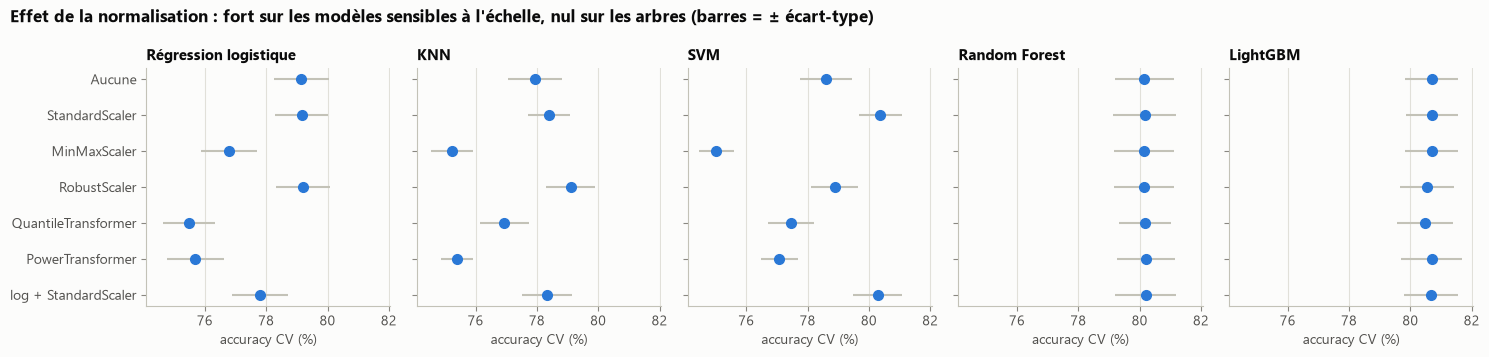

In [24]:
scaling_table = pd.DataFrame({m: {meth: SCORES[scale_keys[m, meth]].mean() for meth in SCALING} for m in MODELS_5})
display(scaling_table.rename(columns=MODEL_LABELS).style.format("{:.4f}").highlight_max(axis=0, props="font-weight: bold"))

fig, axes = plt.subplots(1, len(MODELS_5), figsize=(15, 3.6), sharey=True, sharex=True)  # même échelle partout
methods = list(SCALING)[::-1]
for ax, m in zip(axes, MODELS_5):
    means = [SCORES[scale_keys[m, meth]].mean() * 100 for meth in methods]
    stds = [SCORES[scale_keys[m, meth]].std() * 100 for meth in methods]
    ax.errorbar(means, methods, xerr=stds, fmt="o", color=C_BLUE, ecolor=AXIS, elinewidth=1.5, markersize=7)
    ax.set_title(MODEL_LABELS[m])
    ax.set_xlabel("accuracy CV (%)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Effet de la normalisation : fort sur les modèles sensibles à l'échelle, nul sur les arbres (barres = ± écart-type)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "06_normalisation")

**Lecture des résultats**

L'hypothèse de départ est confirmée, avec quelques surprises.

- **Arbres : aucun effet.** Random Forest et LightGBM restent dans une fourchette de ±0,2 point quelle que soit la transformation, ce qui est normal puisqu'elles conservent toutes l'ordre des valeurs. (Pour le Random Forest, la règle adopte « log + StandardScaler » pour +0,05 point sur 10 folds sur 15 : c'est un cas limite de la règle, sans conséquence pratique.)
- **Modèles sensibles à l'échelle : des écarts de 3 à 5 points** entre la meilleure et la pire méthode. Le SVM perd 1,8 point sans normalisation et 5,4 points avec `MinMaxScaler`.
- **La méthode « par défaut » n'est pas toujours la bonne** : pour le KNN, `RobustScaler` bat `StandardScaler` de +0,7 point (12 folds sur 15). Les dépenses ont quelques valeurs énormes : `StandardScaler` les laisse dominer les distances, `RobustScaler` (médiane et écart interquartile) les atténue.
- **Surprise : les transformations qui « gaussianisent » les données dégradent tout** (`QuantileTransformer`, `PowerTransformer`, log : −1,4 à −3,7 points pour la régression logistique). Les dépenses valent 0 pour deux tiers des passagers ; ces transformations écrasent les grosses dépenses et agrandissent les petites, alors que ce sont justement les gros montants (au spa, au VR deck, en room service) qui signalent un passager non transporté.
- **`MinMaxScaler` est le pire partout** : une seule dépense énorme compresse toutes les autres près de 0.

Leçon : la normalisation compte énormément pour les modèles linéaires, SVM et KNN, pas du tout pour les arbres, et le choix du scaler doit se mesurer, pas se supposer.

---
## Phase 6 — PCA et sélection de features

### PCA

La PCA remplace les features par un plus petit nombre de combinaisons linéaires qui conservent l'essentiel de la **variance**. Elle ne regarde pas la cible : les directions où les données varient le plus ne sont pas forcément celles qui prédisent le mieux. On mesure donc.

D'abord, combien de composantes faut-il pour conserver 90 %, 95 % et 99 % de la variance ?

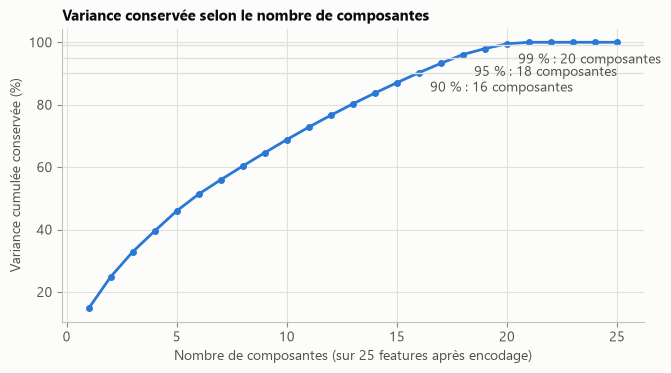

In [25]:
pipe_lr, X_cur, _ = pipe_for("LogReg")
Z = StandardScaler().fit_transform(pipe_lr[:-1].fit_transform(X_cur, y))
cumvar = np.cumsum(PCA().fit(Z).explained_variance_ratio_) * 100

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(range(1, len(cumvar) + 1), cumvar, color=C_BLUE, marker="o", markersize=4)
for level in (90, 95, 99):
    n = int(np.searchsorted(cumvar, level) + 1)
    ax.axhline(level, color=GRID, linewidth=1)
    ax.annotate(f"{level} % : {n} composantes", (n, level), xytext=(8, -13), textcoords="offset points", color=INK_2)
ax.set_xlabel(f"Nombre de composantes (sur {Z.shape[1]} features après encodage)")
ax.set_ylabel("Variance cumulée conservée (%)")
ax.set_title("Variance conservée selon le nombre de composantes")
savefig(fig, "07_pca_variance")

In [26]:
TREE_MODEL = REF_MODEL if REF_MODEL not in SCALE_SENSITIVE else "RandomForest"
PCA_VARIANTS = {
    "PCA 90 % de variance": dict(pca=0.90),
    "PCA 95 % de variance": dict(pca=0.95),
    "PCA 99 % de variance": dict(pca=0.99),
    "PCA sur les dépenses uniquement (3 composantes)": dict(spend_pca=3),
}
pca_keys = {}
for m in ["LogReg", TREE_MODEL]:
    k_ref = BEST_KEY[m]
    pca_keys[m, "Sans PCA"] = k_ref
    print(f"{m} · sans PCA (référence) : {mean_std(k_ref)}")
    # la PCA ne supporte pas les NaN : on impute si le modèle s'en passait
    extra = {"imputer": STATE["fallback_imputer"]} if cfg_for(m)["imputer"] == "none" else {}
    for label, change in PCA_VARIANTS.items():
        pca_keys[m, label] = experiment(6, f"{m} · {label}", m, ref=k_ref, **change, **extra)
    candidates = {pca_keys[m, label]: label for label in PCA_VARIANTS}
    best = best_adopted(candidates, k_ref)
    if best is not None:
        MODEL_CFG[m].update(PCA_VARIANTS[candidates[best]], **extra)
        BEST_KEY[m] = best
    print(f"-> {m} : {'sans PCA' if best is None else candidates[best]}\n")

pca_table = pd.DataFrame({m: {label: mean_std(pca_keys[m, label]) for label in ["Sans PCA", *PCA_VARIANTS]}
                          for m in ["LogReg", TREE_MODEL]}).rename(columns=MODEL_LABELS)
pca_table

LogReg · sans PCA (référence) : 0.7916 ± 0.0087


LogReg · PCA 90 % de variance                        0.7531 ± 0.0117 | gain -0.0385 ( 0/15 folds) -> dégradation nette


LogReg · PCA 95 % de variance                        0.7879 ± 0.0094 | gain -0.0037 ( 3/15 folds) -> perte faible mais régulière


LogReg · PCA 99 % de variance                        0.7917 ± 0.0089 | gain +0.0002 ( 5/15 folds) -> dans le bruit


LogReg · PCA sur les dépenses uniquement (3 composantes) 0.7482 ± 0.0088 | gain -0.0434 ( 0/15 folds) -> dégradation nette
-> LogReg : sans PCA

RandomForest · sans PCA (référence) : 0.8020 ± 0.0099


RandomForest · PCA 90 % de variance                  0.7610 ± 0.0094 | gain -0.0410 ( 0/15 folds) -> dégradation nette


RandomForest · PCA 95 % de variance                  0.7867 ± 0.0101 | gain -0.0153 ( 0/15 folds) -> dégradation nette


RandomForest · PCA 99 % de variance                  0.7886 ± 0.0093 | gain -0.0135 ( 0/15 folds) -> dégradation nette


RandomForest · PCA sur les dépenses uniquement (3 composantes) 0.7620 ± 0.0082 | gain -0.0400 ( 0/15 folds) -> dégradation nette
-> RandomForest : sans PCA



,Régression logistique,Random Forest
Sans PCA,0.7916 ± 0.0087,0.8020 ± 0.0099
PCA 90 % de variance,0.7531 ± 0.0117,0.7610 ± 0.0094
PCA 95 % de variance,0.7879 ± 0.0094,0.7867 ± 0.0101
PCA 99 % de variance,0.7917 ± 0.0089,0.7886 ± 0.0093
PCA sur les dépenses uniquement (3 composantes),0.7482 ± 0.0088,0.7620 ± 0.0082


### Sélection de features

Retirer des features peut aider si certaines n'apportent que du bruit. Trois méthodes, toutes **à l'intérieur du pipeline** (choisir les features sur tout le train avant la validation croisée serait une fuite : la sélection aurait vu les réponses des folds de validation) :

- **importance** : on garde la moitié des features les plus importantes pour un Random Forest ;
- **RFECV** : élimination récursive, le nombre de features gardées est choisi par une validation croisée interne ;
- **permutation importance** : on garde les features dont le mélange aléatoire dégrade le score sur un échantillon mis de côté.

D'abord, un coup d'œil à la permutation importance des colonnes (sur un fold de validation) :

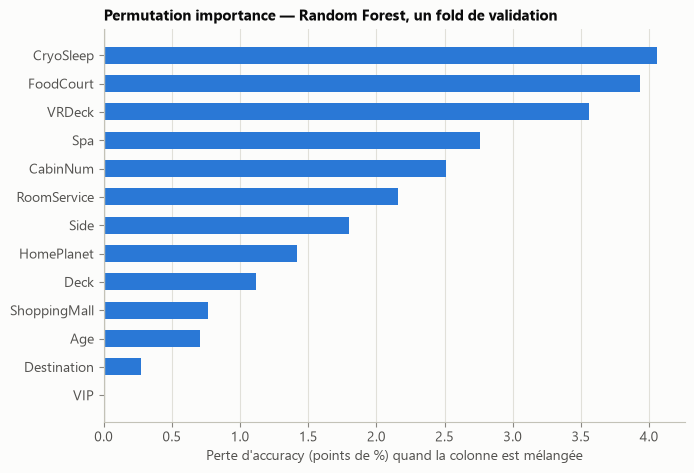

In [27]:
pipe_ref, X_cur, _ = pipe_for(REF_MODEL)
tr, va = SPLITS[0]
pipe_ref.fit(X_cur.iloc[tr], y[tr])
imp = permutation_importance(pipe_ref, X_cur.iloc[va], y[va], n_repeats=10, scoring="accuracy", random_state=SEED, n_jobs=N_JOBS)
imp = pd.Series(imp.importances_mean * 100, index=X_cur.columns).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 0.3 * len(imp) + 1.2))
ax.barh(imp.index, imp.values, height=0.6, color=C_BLUE)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlabel("Perte d'accuracy (points de %) quand la colonne est mélangée")
ax.set_title(f"Permutation importance — {MODEL_LABELS[REF_MODEL]}, un fold de validation")
ax.grid(axis="y", visible=False)
savefig(fig, "08_permutation_importance")

In [28]:
SELECTORS = {"importance": "importance (moitié supérieure)", "rfecv": "RFECV", "permutation": "permutation importance"}
k_ref = BEST_KEY[REF_MODEL]
print(f"{REF_MODEL} · toutes les features (référence) : {mean_std(k_ref)}")
sel_keys = {experiment(6, f"sélection : {label}", REF_MODEL, ref=k_ref, selector=kind): kind for kind, label in SELECTORS.items()}
best = best_adopted(sel_keys, k_ref)
if best is not None:
    MODEL_CFG.setdefault(REF_MODEL, {})["selector"] = sel_keys[best]
    BEST_KEY[REF_MODEL] = best
current = BEST_KEY[REF_MODEL]
print(f"-> sélection retenue : {'aucune' if best is None else SELECTORS[sel_keys[best]]}")

RandomForest · toutes les features (référence) : 0.8020 ± 0.0099


sélection : importance (moitié supérieure)           0.7878 ± 0.0087 | gain -0.0143 ( 1/15 folds) -> dégradation nette


sélection : RFECV                                    0.8024 ± 0.0092 | gain +0.0003 ( 7/15 folds) -> dans le bruit


sélection : permutation importance                   0.7962 ± 0.0087 | gain -0.0059 ( 3/15 folds) -> perte faible mais régulière
-> sélection retenue : aucune


**Lecture des résultats**

- **La PCA n'aide jamais, et nuit souvent beaucoup.** Pour le Random Forest, toutes les variantes perdent de 1,4 à 4,1 points, sur les 15 folds. Pour la régression logistique, PCA 99 % égale le score sans PCA (normal : garder 99 % de la variance revient presque à tout garder), et PCA 90 % perd 3,9 points.
- **Pourquoi ?** Les features ne sont pas redondantes (il faut beaucoup de composantes pour garder l'essentiel de la variance, voir la courbe), et la PCA ne regarde pas la cible : elle garde les directions où les données varient le plus, pas celles qui séparent les transportés des autres. Pour les arbres, c'est encore pire : chaque composante mélange toutes les colonnes, et un arbre ne peut plus faire de coupures simples comme « `CryoSleep` = 1 » ou « `Spa` > 0 ».
- **PCA sur les dépenses seulement** : −4 points pour les deux modèles. Les 5 services ne portent pas la même information (certains sont liés au fait d'être transporté, d'autres à l'inverse) ; les compresser en 3 axes détruit précisément ce contraste.
- **Sélection de features** : RFECV égale le score de référence (+0,03 point, dans le bruit) ; garder la moitié des features selon l'importance (−1,4 point) ou selon la permutation importance (−0,6 point) dégrade le score. Avec une vingtaine de features presque toutes utiles, il n'y a pas grand-chose à retirer.

Leçon : la PCA et la sélection de features sont utiles quand il y a beaucoup de features redondantes ou bruitées (images, texte, génomique…). Sur un petit jeu tabulaire aux features bien construites, elles retirent de l'information.

---
## Phase 7 — Comparaison de 13 modèles

Tous les modèles reçoivent les mêmes features (celles retenues en phase 2) et le prétraitement qui leur convient d'après les phases 3 à 6 :

- modèles sensibles à l'échelle : normalisation retenue en phase 5 ;
- modèles à base d'arbres : pas de normalisation ;
- modèles de boosting : valeurs manquantes et catégories natives seulement si la mesure l'a justifié.

Les hyperparamètres sont ceux par défaut (ou des valeurs usuelles) : le tuning vient ensuite, sur les meilleurs seulement. La colonne « gain » compare chaque modèle au modèle de référence des phases précédentes.

In [29]:
pd.DataFrame({MODEL_LABELS[m]: {k: str(v) for k, v in cfg_for(m).items() if k in ("imputer", "encoder", "scaler", "log_spend", "pca")}
              for m in MODEL_LABELS}).T

,imputer,encoder,scaler,log_spend,pca
Régression logistique,median,onehot,standard,False,None
KNN,median,onehot,robust,False,None
SVM,median,onehot,standard,False,None
Naive Bayes,median,onehot,standard,False,None
Arbre de décision,median,onehot,None,False,None
Random Forest,median,onehot,standard,True,None
Extra Trees,median,onehot,None,False,None
Gradient Boosting,median,onehot,None,False,None
HistGradientBoosting,median,onehot,None,False,None
XGBoost,median,onehot,None,False,None


In [30]:
K_REF_MODEL = BEST_KEY[REF_MODEL]
model_keys = {m: experiment(7, MODEL_LABELS[m], m, ref=K_REF_MODEL) for m in MODEL_LABELS}
ranking = sorted(model_keys, key=lambda m: -SCORES[model_keys[m]].mean())
BEST_MODEL = ranking[0]
PROGRESS.append(("+ Meilleur modèle", model_keys[BEST_MODEL]))

Régression logistique                                0.7916 ± 0.0087 | gain -0.0104 ( 1/15 folds) -> dégradation nette


KNN                                                  0.7910 ± 0.0080 | gain -0.0110 ( 1/15 folds) -> dégradation nette


SVM                                                  0.8037 ± 0.0071 | gain +0.0017 ( 8/15 folds) -> dans le bruit


Naive Bayes                                          0.7119 ± 0.0442 | gain -0.0901 ( 0/15 folds) -> dégradation nette


Arbre de décision                                    0.7668 ± 0.0095 | gain -0.0352 ( 0/15 folds) -> dégradation nette


...

HistGradientBoosting                                 0.8079 ± 0.0094 | gain +0.0059 (11/15 folds) -> gain faible mais régulier


XGBoost                                              0.8053 ± 0.0097 | gain +0.0033 ( 9/15 folds) -> dans le bruit


LightGBM                                             0.8069 ± 0.0086 | gain +0.0049 (11/15 folds) -> gain faible mais régulier


CatBoost                                             0.8109 ± 0.0094 | gain +0.0089 (12/15 folds) -> gain faible mais régulier


Réseau de neurones (MLP)                             0.7993 ± 0.0084 | gain -0.0027 ( 5/15 folds) -> perte faible mais régulière


,Modèle,Accuracy CV (moyenne ± écart-type)
0,CatBoost,0.8109 ± 0.0094
1,HistGradientBoosting,0.8079 ± 0.0094
2,LightGBM,0.8069 ± 0.0086
3,XGBoost,0.8053 ± 0.0097
4,SVM,0.8037 ± 0.0071
5,Gradient Boosting,0.8031 ± 0.0092
6,Random Forest,0.8020 ± 0.0099
7,Réseau de neurones (MLP),0.7993 ± 0.0084
8,Extra Trees,0.7941 ± 0.0126
9,Régression logistique,0.7916 ± 0.0087


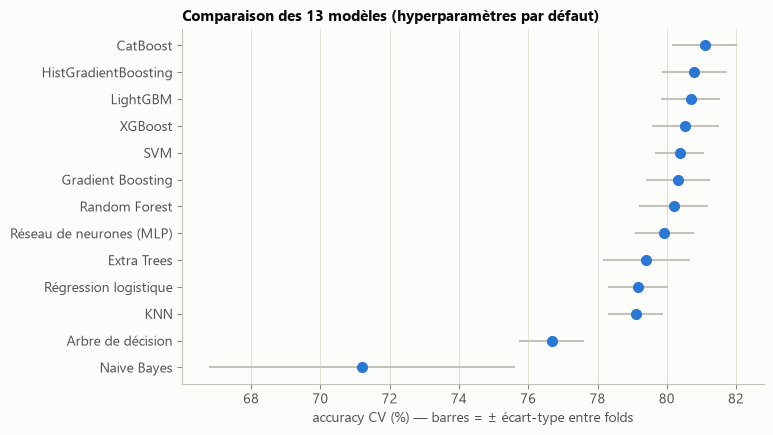

In [31]:
models_table = pd.DataFrame({"Modèle": [MODEL_LABELS[m] for m in ranking],
                             "Accuracy CV (moyenne ± écart-type)": [mean_std(model_keys[m]) for m in ranking]})
display(models_table)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
order = ranking[::-1]
ax.errorbar([SCORES[model_keys[m]].mean() * 100 for m in order], [MODEL_LABELS[m] for m in order],
            xerr=[SCORES[model_keys[m]].std() * 100 for m in order], fmt="o", color=C_BLUE, ecolor=AXIS,
            elinewidth=1.5, markersize=7)
ax.set_xlabel("accuracy CV (%) — barres = ± écart-type entre folds")
ax.set_title("Comparaison des 13 modèles (hyperparamètres par défaut)")
ax.grid(axis="y", visible=False)
savefig(fig, "09_modeles")

<!--OBS:phase7-->

### Les décisions des phases 2 et 3 tiennent-elles avec le meilleur modèle ?

Les features et l'imputation ont été choisies avec le modèle de référence. Un modèle plus puissant peut tirer parti de features que le premier n'exploitait pas. Avant de passer au tuning, on re-teste donc avec le meilleur modèle — toujours un changement à la fois, même règle de décision — les groupes de features rejetés en phase 2 et l'imputation logique.

In [32]:
k_best = model_keys[BEST_MODEL]
groups_before, logical_before = list(STATE["groups"]), STATE["logical"]
print(f"{BEST_MODEL} (référence) : {mean_std(k_best)}")

for g in [g for g in GROUP_LABELS if g not in STATE["groups"]]:
    k = experiment(7, f"{BEST_MODEL} · + {GROUP_LABELS[g]}", BEST_MODEL, ref=k_best, groups=STATE["groups"] + [g])
    if compare(k, k_best)["adopted"]:
        STATE["groups"].append(g)
        k_best = k
if not STATE["logical"]:
    k = experiment(7, f"{BEST_MODEL} · + imputation logique", BEST_MODEL, ref=k_best, logical=True)
    if compare(k, k_best)["adopted"]:
        STATE["logical"], k_best = True, k

REVISED = STATE["groups"] != groups_before or STATE["logical"] != logical_before
print(f"\nGroupes de features : {STATE['groups']} | imputation logique : {STATE['logical']}")

# Les 3 meilleurs modèles partent au tuning ; leur score de départ est mesuré dans la configuration finale
TOP3 = ranking[:3]
K_UNTUNED = {}
for m in TOP3:
    if not REVISED:
        K_UNTUNED[m] = model_keys[m]
    elif m == BEST_MODEL:
        K_UNTUNED[m] = k_best
    else:
        K_UNTUNED[m] = experiment(7, f"{MODEL_LABELS[m]} (configuration révisée)", m, ref=model_keys[m])
if REVISED:
    PROGRESS.append(("+ Features revues avec le meilleur modèle", k_best))
print("Modèles retenus pour le tuning :", [MODEL_LABELS[m] for m in TOP3])

CatBoost (référence) : 0.8109 ± 0.0094


CatBoost · + GroupSize, IsAlone                      0.8115 ± 0.0084 | gain +0.0006 ( 8/15 folds) -> dans le bruit


CatBoost · + TotalSpend, NoSpend                     0.8172 ± 0.0093 | gain +0.0063 (14/15 folds) -> gain faible mais régulier


CatBoost · + AgeGroup, IsChild                       0.8171 ± 0.0089 | gain -0.0000 ( 5/15 folds) -> dans le bruit


CatBoost · + FamilySize                              0.8153 ± 0.0081 | gain -0.0018 ( 5/15 folds) -> dans le bruit


CatBoost · + Indicateurs de valeurs manquantes       0.8162 ± 0.0084 | gain -0.0010 ( 4/15 folds) -> perte faible mais régulière


CatBoost · + imputation logique                      0.8145 ± 0.0085 | gain -0.0026 ( 1/15 folds) -> perte faible mais régulière

Groupes de features : ['base', 'cabin', 'spend'] | imputation logique : False


HistGradientBoosting (configuration révisée)         0.8111 ± 0.0095 | gain +0.0032 (10/15 folds) -> gain faible mais régulier


LightGBM (configuration révisée)                     0.8103 ± 0.0085 | gain +0.0035 (10/15 folds) -> gain faible mais régulier
Modèles retenus pour le tuning : ['CatBoost', 'HistGradientBoosting', 'LightGBM']


<!--OBS:phase7b-->

---
## Phase 8 — Tuning des hyperparamètres avec Optuna

Les 3 meilleurs modèles de la phase 7 sont optimisés avec **Optuna** :

- l'échantillonneur **TPE** propose des combinaisons d'hyperparamètres en s'appuyant sur les essais précédents (plutôt qu'une grille ou du hasard pur) ;
- le **pruning** (`MedianPruner`) abandonne un essai dès que son score partiel, fold après fold, passe sous la médiane des essais précédents.

Pour limiter le temps de calcul, chaque essai est évalué sur les 5 folds de la première répétition. Les meilleurs hyperparamètres sont ensuite **réévalués avec le protocole complet** (15 folds) et ne sont gardés que s'ils passent la règle de décision face aux hyperparamètres par défaut.

In [33]:
N_TRIALS = 30


def suggest(model, t):
    """Espace de recherche de chaque modèle."""
    if model == "LightGBM":
        return dict(n_estimators=t.suggest_int("n_estimators", 200, 1000, step=50),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                    num_leaves=t.suggest_int("num_leaves", 8, 64),
                    min_child_samples=t.suggest_int("min_child_samples", 5, 60),
                    subsample=t.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
                    colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
                    reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True))
    if model == "XGBoost":
        return dict(n_estimators=t.suggest_int("n_estimators", 200, 1000, step=50),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                    max_depth=t.suggest_int("max_depth", 3, 8),
                    min_child_weight=t.suggest_int("min_child_weight", 1, 10),
                    subsample=t.suggest_float("subsample", 0.6, 1.0),
                    colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
                    reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True),
                    gamma=t.suggest_float("gamma", 0.0, 5.0))
    if model == "CatBoost":
        return dict(iterations=t.suggest_int("iterations", 300, 800, step=50),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                    depth=t.suggest_int("depth", 4, 7),
                    l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
                    random_strength=t.suggest_float("random_strength", 0.0, 2.0))
    if model == "HistGB":
        return dict(max_iter=t.suggest_int("max_iter", 100, 600, step=50),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                    max_leaf_nodes=t.suggest_int("max_leaf_nodes", 8, 64),
                    min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 60),
                    l2_regularization=t.suggest_float("l2_regularization", 1e-3, 10, log=True))
    if model == "GradientBoosting":
        return dict(n_estimators=t.suggest_int("n_estimators", 100, 500, step=50),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                    max_depth=t.suggest_int("max_depth", 2, 5),
                    subsample=t.suggest_float("subsample", 0.6, 1.0),
                    min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 30))
    if model in ("RandomForest", "ExtraTrees"):
        return dict(n_estimators=t.suggest_int("n_estimators", 200, 600, step=100),
                    max_depth=t.suggest_int("max_depth", 5, 20),
                    min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 10),
                    max_features=t.suggest_float("max_features", 0.3, 1.0))
    if model == "SVM":
        return dict(C=t.suggest_float("C", 0.1, 30, log=True), gamma=t.suggest_float("gamma", 1e-3, 1, log=True))
    if model == "LogReg":
        return dict(C=t.suggest_float("C", 1e-2, 100, log=True))
    if model == "KNN":
        return dict(n_neighbors=t.suggest_int("n_neighbors", 5, 60),
                    weights=t.suggest_categorical("weights", ["uniform", "distance"]))
    if model == "MLP":
        sizes = {"64": (64,), "128": (128,), "64-32": (64, 32), "128-64": (128, 64)}
        return dict(hidden_layer_sizes=sizes[t.suggest_categorical("hidden_layer_sizes", list(sizes))],
                    alpha=t.suggest_float("alpha", 1e-5, 1e-1, log=True),
                    learning_rate_init=t.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True))
    if model == "DecisionTree":
        return dict(max_depth=t.suggest_int("max_depth", 3, 15), min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 50))
    if model == "NaiveBayes":
        return dict(var_smoothing=t.suggest_float("var_smoothing", 1e-10, 1e-2, log=True))
    raise ValueError(model)


def fit_score(model, params, tr, va, threads):
    pipe, X, _ = pipe_for(model, threads=threads, params=params)
    return pipe.fit(X.iloc[tr], y[tr]).score(X.iloc[va], y[va])


def tune(model, n_trials=N_TRIALS):
    tune_splits = SPLITS[:N_SPLITS]  # première répétition

    def objective(trial):
        params = suggest(model, trial)
        if model in THREADED:  # folds l'un après l'autre (modèle multi-cœurs) -> pruning possible entre deux folds
            scores = []
            for step, (tr, va) in enumerate(tune_splits):
                scores.append(fit_score(model, params, tr, va, N_THREADS))
                trial.report(float(np.mean(scores)), step)
                if trial.should_prune():
                    raise optuna.TrialPruned()
        else:                  # modèle mono-cœur : les 5 folds en parallèle
            scores = Parallel(n_jobs=N_SPLITS)(delayed(fit_score)(model, params, tr, va, 1) for tr, va in tune_splits)
        return float(np.mean(scores))

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=8))
    study.optimize(objective, n_trials=n_trials)
    return study

In [34]:
K_TUNED, STUDIES = {}, {}
for m in TOP3:
    t = time.time()
    STUDIES[m] = study = tune(m)
    best_params = suggest(m, optuna.trial.FixedTrial(study.best_params))
    n_pruned = sum(tr.state == optuna.trial.TrialState.PRUNED for tr in study.trials)
    print(f"\n{MODEL_LABELS[m]} : {len(study.trials)} essais dont {n_pruned} abandonnés tôt, {time.time() - t:.0f} s")
    print("  meilleurs hyperparamètres :", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})
    k = experiment(8, f"{MODEL_LABELS[m]} (tuné)", m, ref=K_UNTUNED[m], params=best_params, note=str(best_params))
    if compare(k, K_UNTUNED[m])["adopted"]:
        PARAMS[m], K_TUNED[m] = best_params, k
    else:
        K_TUNED[m] = K_UNTUNED[m]
        print("  -> gain non confirmé sur les 15 folds : on garde les hyperparamètres par défaut")

BEST_SINGLE = max(TOP3, key=lambda m: SCORES[K_TUNED[m]].mean())
K_BEST_SINGLE = K_TUNED[BEST_SINGLE]
PROGRESS.append(("+ Tuning", K_BEST_SINGLE))
milestone("03_apres_tuning", K_BEST_SINGLE, BEST_SINGLE)


CatBoost : 30 essais dont 12 abandonnés tôt, 516 s
  meilleurs hyperparamètres : {'iterations': 800, 'learning_rate': 0.0122, 'depth': 7, 'l2_leaf_reg': 5.601, 'random_strength': 0.6527}


CatBoost (tuné)                                      0.8165 ± 0.0085 | gain -0.0007 ( 7/15 folds) -> dans le bruit
  -> gain non confirmé sur les 15 folds : on garde les hyperparamètres par défaut



HistGradientBoosting : 30 essais dont 16 abandonnés tôt, 116 s
  meilleurs hyperparamètres : {'max_iter': 450, 'learning_rate': 0.0996, 'max_leaf_nodes': 14, 'min_samples_leaf': 11, 'l2_regularization': 0.1134}


HistGradientBoosting (tuné)                          0.8118 ± 0.0095 | gain +0.0007 ( 8/15 folds) -> dans le bruit
  -> gain non confirmé sur les 15 folds : on garde les hyperparamètres par défaut



LightGBM : 30 essais dont 5 abandonnés tôt, 204 s
  meilleurs hyperparamètres : {'n_estimators': 700, 'learning_rate': 0.0115, 'num_leaves': 42, 'min_child_samples': 14, 'subsample': 0.626, 'subsample_freq': 1, 'colsample_bytree': 0.9744, 'reg_lambda': 7.2867}


LightGBM (tuné)                                      0.8115 ± 0.0107 | gain +0.0011 ( 7/15 folds) -> dans le bruit
  -> gain non confirmé sur les 15 folds : on garde les hyperparamètres par défaut


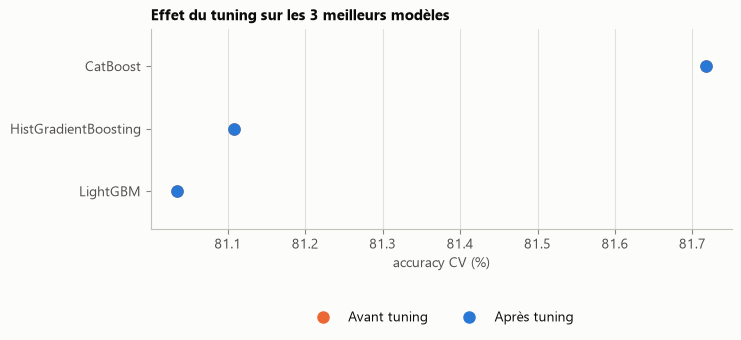

Gain du feature engineering (phase 2) : +0.0152
Gain du choix du modèle (phase 7)     : +0.0089
Gain du tuning (phase 8)              : +0.0000


In [35]:
fig, ax = plt.subplots(figsize=(7.5, 2.6))
labels = [MODEL_LABELS[m] for m in TOP3][::-1]
before = [SCORES[K_UNTUNED[m]].mean() * 100 for m in TOP3][::-1]
after = [SCORES[K_TUNED[m]].mean() * 100 for m in TOP3][::-1]
ax.hlines(labels, before, after, color=AXIS, linewidth=2)
ax.plot(before, labels, "o", color=C_ORANGE, markersize=8, label="Avant tuning")
ax.plot(after, labels, "o", color=C_BLUE, markersize=8, label="Après tuning")
ax.set_xlabel("accuracy CV (%)")
ax.set_title("Effet du tuning sur les 3 meilleurs modèles")
ax.margins(y=0.3)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2)
savefig(fig, "10_tuning")

gain_fe = SCORES[K_FE].mean() - SCORES[K_BASELINE].mean()
gain_model = SCORES[model_keys[BEST_MODEL]].mean() - SCORES[K_REF_MODEL].mean()
gain_tuning = SCORES[K_BEST_SINGLE].mean() - max(SCORES[K_UNTUNED[m]].mean() for m in TOP3)
print(f"Gain du feature engineering (phase 2) : {gain_fe:+.4f}")
print(f"Gain du choix du modèle (phase 7)     : {gain_model:+.4f}")
print(f"Gain du tuning (phase 8)              : {gain_tuning:+.4f}")

<!--OBS:phase8-->

---
## Phase 9 — Ensembles

Combiner plusieurs modèles peut corriger leurs erreurs individuelles — à condition qu'ils ne fassent pas tous les **mêmes** erreurs.

On commence par calculer, pour chaque modèle candidat, ses **probabilités hors-fold** (*out-of-fold*) : pour chaque passager, la probabilité prédite par le modèle entraîné sans lui. Avec les mêmes folds que d'habitude, cela permet d'évaluer une moyenne de modèles sans rien ré-entraîner.

Candidats : les 3 modèles tunés, plus le meilleur modèle d'une **autre famille** (non basé sur des arbres), pour apporter de la diversité.

In [36]:
def member_pipe(model, seed=SEED):
    """Pipeline d'un membre d'ensemble (avec ses hyperparamètres retenus), capable de prédire des probabilités."""
    params = {**PARAMS.get(model, {}), **({"probability": True} if model == "SVM" else {})}
    return pipe_for(model, seed=seed, params=params)[0]


def oof_proba(model, seed=SEED):
    """Probabilités hors-fold : tableau (répétition, passager)."""
    pipe, (X, _, _) = member_pipe(model, seed), get_data(STATE["groups"], STATE["logical"])

    def one(tr, va):
        return clone(pipe).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[va])[:, 1]

    preds = Parallel(n_jobs=N_JOBS)(delayed(one)(tr, va) for tr, va in SPLITS)
    P = np.zeros((N_REPEATS, n_train))
    for i, (tr, va) in enumerate(SPLITS):
        P[i // N_SPLITS, va] = preds[i]
    return P


def fold_scores(P):
    """Les 15 scores d'accuracy correspondant à des probabilités hors-fold."""
    return np.array([((P[i // N_SPLITS, va] > 0.5).astype(int) == y[va]).mean() for i, (tr, va) in enumerate(SPLITS)])


DIVERSE = next(m for m in ranking if m in SCALE_SENSITIVE and m not in TOP3)
MEMBERS = TOP3 + [DIVERSE]
OOF = {m: oof_proba(m) for m in MEMBERS}
for m in MEMBERS:
    print(f"{MODEL_LABELS[m]:<28} accuracy hors-fold : {fold_scores(OOF[m]).mean():.4f}")

CatBoost                     accuracy hors-fold : 0.8172
HistGradientBoosting         accuracy hors-fold : 0.8111
LightGBM                     accuracy hors-fold : 0.8103
SVM                          accuracy hors-fold : 0.8024


### Les modèles sont-ils différents ?

Deux mesures : la **corrélation** entre les probabilités prédites, et le **taux de désaccord** (part des passagers pour lesquels deux modèles prédisent une classe différente). Des modèles corrélés à 0,99 font les mêmes erreurs : les moyenner n'apporte rien.

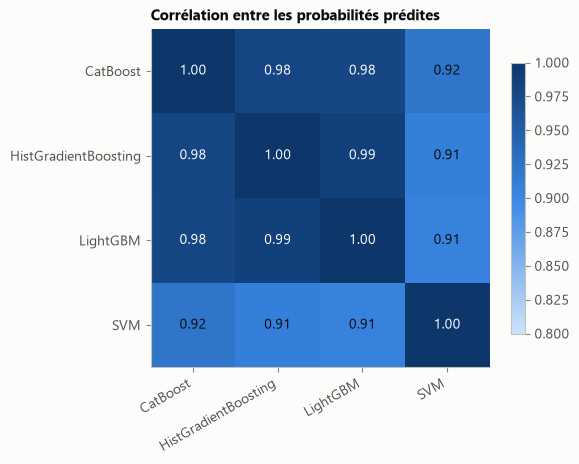

Taux de désaccord entre modèles :


,CatBoost,HistGradientBoosting,LightGBM,SVM
CatBoost,0.0 %,5.4 %,5.8 %,9.4 %
HistGradientBoosting,5.4 %,0.0 %,4.6 %,9.9 %
LightGBM,5.8 %,4.6 %,0.0 %,10.9 %
SVM,9.4 %,9.9 %,10.9 %,0.0 %


In [37]:
labels = [MODEL_LABELS[m] for m in MEMBERS]
corr = np.corrcoef([OOF[m][0] for m in MEMBERS])
disagree = pd.DataFrame([[((OOF[a][0] > 0.5) != (OOF[b][0] > 0.5)).mean() for b in MEMBERS] for a in MEMBERS],
                        index=labels, columns=labels)

fig, ax = plt.subplots(figsize=(5.6, 4.4))
im = ax.imshow(corr, cmap=CMAP_BLUE, vmin=min(0.8, corr.min()), vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", color="white" if corr[i, j] > 0.93 else INK)
ax.grid(False)
ax.set_title("Corrélation entre les probabilités prédites")
fig.colorbar(im, ax=ax, shrink=0.8)
savefig(fig, "11_correlation_modeles")

print("Taux de désaccord entre modèles :")
display(disagree.map(lambda v: pct(v, 1)))

### Cinq façons de combiner

1. **Moyenne simple** des probabilités des 3 meilleurs modèles.
2. **Moyenne simple + le modèle d'une autre famille**.
3. **Moyenne pondérée** des 4 modèles. Pour ne pas tricher, les poids utilisés sur un fold sont choisis sur les *autres* folds.
4. **Stacking** : une régression logistique apprend à combiner les probabilités des 3 meilleurs modèles (`StackingClassifier`, ré-entraîné dans chaque fold).
5. **Moyenne de 5 seeds** du meilleur modèle : même modèle, 5 initialisations aléatoires différentes.

Référence : le meilleur modèle seul après tuning.

In [38]:
ens_keys = {}
print(f"Référence — {MODEL_LABELS[BEST_SINGLE]} seul : {mean_std(K_BEST_SINGLE)}\n")

# 1 et 2 : moyennes simples
ens_keys["avg3"] = log_experiment(9, "moyenne des 3 meilleurs modèles", fold_scores(np.mean([OOF[m] for m in TOP3], axis=0)),
                                  ref=K_BEST_SINGLE)
ens_keys["avg4"] = log_experiment(9, f"moyenne des 3 meilleurs + {MODEL_LABELS[DIVERSE]}",
                                  fold_scores(np.mean([OOF[m] for m in MEMBERS], axis=0)), ref=K_BEST_SINGLE)

# 3 : moyenne pondérée, poids sur une grille de pas 0,1 (somme = 1)
grid = np.array([w for w in np.ndindex(11, 11, 11, 11) if sum(w) == 10]) / 10
stack = np.stack([OOF[m] for m in MEMBERS])  # (modèle, répétition, passager)


def best_weights(rep_idx_pairs):
    """Poids de la grille qui maximisent l'accuracy sur les (répétition, indices) donnés."""
    acc = np.zeros(len(grid))
    for rep, idx in rep_idx_pairs:
        acc += (((grid @ stack[:, rep, idx]) > 0.5) == y[idx]).mean(axis=1)
    return grid[acc.argmax()]


weighted_scores = []
for i, (tr, va) in enumerate(SPLITS):
    rep = i // N_SPLITS
    w = best_weights([(rep, tr)])  # poids choisis sans regarder le fold évalué
    weighted_scores.append((((w @ stack[:, rep, va]) > 0.5) == y[va]).mean())
ens_keys["weighted"] = log_experiment(9, "moyenne pondérée (poids choisis hors fold)", weighted_scores, ref=K_BEST_SINGLE)
WEIGHTS = best_weights([(rep, np.arange(n_train)) for rep in range(N_REPEATS)])
print("   poids sur toutes les données :", dict(zip(labels, WEIGHTS)))

# 4 : stacking
X_cur, X_test_cur, _ = get_data(STATE["groups"], STATE["logical"])
stacking = StackingClassifier([(m, member_pipe(m)) for m in TOP3], final_estimator=LogisticRegression(),
                              cv=5, stack_method="predict_proba")
ens_keys["stacking"] = run(9, "stacking (régression logistique)", stacking, X_cur, ref=K_BEST_SINGLE)

# 5 : moyenne de seeds
SEEDS = [SEED + s for s in range(5)]
oof_seeds = [OOF[BEST_SINGLE]] + [oof_proba(BEST_SINGLE, seed=s) for s in SEEDS[1:]]
ens_keys["seeds"] = log_experiment(9, f"moyenne de 5 seeds ({MODEL_LABELS[BEST_SINGLE]})",
                                   fold_scores(np.mean(oof_seeds, axis=0)), ref=K_BEST_SINGLE)

Référence — CatBoost seul : 0.8172 ± 0.0093

moyenne des 3 meilleurs modèles                      0.8145 ± 0.0092 | gain -0.0026 ( 2/15 folds) -> perte faible mais régulière
moyenne des 3 meilleurs + SVM                        0.8143 ± 0.0087 | gain -0.0028 ( 4/15 folds) -> perte faible mais régulière


moyenne pondérée (poids choisis hors fold)           0.8148 ± 0.0087 | gain -0.0023 ( 5/15 folds) -> perte faible mais régulière
   poids sur toutes les données : {'CatBoost': np.float64(0.8), 'HistGradientBoosting': np.float64(0.1), 'LightGBM': np.float64(0.0), 'SVM': np.float64(0.1)}


stacking (régression logistique)                     0.8159 ± 0.0090 | gain -0.0013 ( 6/15 folds) -> dans le bruit


moyenne de 5 seeds (CatBoost)                        0.8161 ± 0.0088 | gain -0.0011 ( 3/15 folds) -> dans le bruit


In [39]:
best = best_adopted(ens_keys.values(), K_BEST_SINGLE)
FINAL_KIND = "single" if best is None else next(kind for kind, k in ens_keys.items() if k == best)
K_FINAL = K_BEST_SINGLE if best is None else best
K_BEST_ENSEMBLE = max(ens_keys.values(), key=lambda k: SCORES[k].mean())
PROGRESS.append(("+ Ensemble", K_BEST_ENSEMBLE))
show_phase(9)
print("Ensemble adopté :" if best else "Aucun ensemble ne passe la règle de décision -> on garde le meilleur modèle seul :",
      K_FINAL.split(" · ", 1)[1], f"({mean_std(K_FINAL)})")

,experiment,accuracy CV,gain,folds gagnés,verdict
0,moyenne des 3 meilleurs modèles,0.8145 ± 0.0092,-0.0026,2/15,perte faible mais régulière
1,moyenne des 3 meilleurs + SVM,0.8143 ± 0.0087,-0.0028,4/15,perte faible mais régulière
2,moyenne pondérée (poids choisis hors fold),0.8148 ± 0.0087,-0.0023,5/15,perte faible mais régulière
3,stacking (régression logistique),0.8159 ± 0.0090,-0.0013,6/15,dans le bruit
4,moyenne de 5 seeds (CatBoost),0.8161 ± 0.0088,-0.0011,3/15,dans le bruit


Aucun ensemble ne passe la règle de décision -> on garde le meilleur modèle seul : CatBoost · + TotalSpend, NoSpend (0.8172 ± 0.0093)


<!--OBS:phase9-->

---
## Phase 10 — Solution finale et soumission

La configuration retenue est ré-entraînée sur **tout** le train, puis utilisée pour prédire le test. On génère aussi les soumissions des étapes intermédiaires, pour comparer validation croisée et classement Kaggle à chaque étape.

In [40]:
def build_final(kind):
    if kind == "single":
        return member_pipe(BEST_SINGLE)
    if kind == "avg3":
        return VotingClassifier([(m, member_pipe(m)) for m in TOP3], voting="soft")
    if kind == "avg4":
        return VotingClassifier([(m, member_pipe(m)) for m in MEMBERS], voting="soft")
    if kind == "weighted":
        used = [(m, w) for m, w in zip(MEMBERS, WEIGHTS) if w > 0]
        return VotingClassifier([(m, member_pipe(m)) for m, _ in used], voting="soft", weights=[w for _, w in used])
    if kind == "stacking":
        return stacking
    if kind == "seeds":
        return VotingClassifier([(f"seed{s}", member_pipe(BEST_SINGLE, seed=s)) for s in SEEDS], voting="soft")
    raise ValueError(kind)


final_model = build_final(FINAL_KIND)
MILESTONES["04_solution_finale"] = (final_model, X_cur, X_test_cur, K_FINAL)

rows = []
for name, (pipe, X_tr, X_te, key) in MILESTONES.items():
    pred = clone(pipe).fit(X_tr, y).predict(X_te).astype(bool)
    path = SUB_DIR / f"submission_{name}.csv"
    pd.DataFrame({"PassengerId": test["PassengerId"], "Transported": pred}).to_csv(path, index=False)
    rows.append({"Fichier": path.as_posix(), "Étape": key.split(" · ", 1)[1], "Accuracy CV": mean_std(key),
                 "% prédits transportés": pct(pred.mean(), 1)})
submissions_table = pd.DataFrame(rows)
submissions_table

,Fichier,Étape,Accuracy CV,% prédits transportés
0,submissions/submission_01_baseline.csv,Random Forest (colonnes brutes),0.7863 ± 0.0082,51.6 %
1,submissions/submission_02_apres_feature_engine...,"cumul : + Deck, CabinNum, Side",0.8015 ± 0.0096,46.6 %
2,submissions/submission_03_apres_tuning.csv,"CatBoost · + TotalSpend, NoSpend",0.8172 ± 0.0093,51.4 %
3,submissions/submission_04_solution_finale.csv,"CatBoost · + TotalSpend, NoSpend",0.8172 ± 0.0093,51.4 %


### Dernière vérification : validation croisée par groupes

Les passagers d'un même groupe se ressemblent (même cabine, même planète) et ont souvent le même sort. Avec un découpage classique, un groupe peut être coupé entre entraînement et validation, ce qui peut rendre le score légèrement optimiste. Or, dans le vrai test, **aucun groupe n'est partagé avec le train** (vérifié en phase 0). On réévalue donc la solution finale avec `StratifiedGroupKFold`, qui garde chaque groupe entier dans un seul fold (5 folds × 3 répétitions également).

In [41]:
group_splits = [s for rep in range(N_REPEATS)
                for s in StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED + rep).split(X_cur, y, GROUPS_TRAIN)]
t = time.time()
scores_group = cross_val_score(final_model, X_cur, y, cv=group_splits, scoring="accuracy", n_jobs=N_JOBS)
K_GROUP = log_experiment(10, "solution finale · validation par groupes", scores_group, seconds=time.time() - t,
                         note="StratifiedGroupKFold : folds différents, non appariés avec les autres expériences")
print(f"\nValidation classique   : {mean_std(K_FINAL)}")
print(f"Validation par groupes : {mean_std(K_GROUP)}  (écart : {SCORES[K_GROUP].mean() - SCORES[K_FINAL].mean():+.4f})")

solution finale · validation par groupes             0.8172 ± 0.0076

Validation classique   : 0.8172 ± 0.0093
Validation par groupes : 0.8172 ± 0.0076  (écart : +0.0000)


### Que vaut le feature engineering sur le modèle final ?

Test d'ablation : le meilleur modèle, avec ses hyperparamètres tunés, mais sur les colonnes brutes seulement.

In [42]:
k_ablation = experiment(10, f"ablation · {MODEL_LABELS[BEST_SINGLE]} tuné, colonnes brutes seulement", BEST_SINGLE,
                        ref=K_BEST_SINGLE, groups=["base"], logical=False)
print(f"-> le feature engineering apporte {SCORES[K_BEST_SINGLE].mean() - SCORES[k_ablation].mean():+.4f} au modèle final")

ablation · CatBoost tuné, colonnes brutes seulement  0.7938 ± 0.0096 | gain -0.0234 ( 0/15 folds) -> dégradation nette
-> le feature engineering apporte +0.0234 au modèle final


<!--OBS:phase10-->

---
## Phase 11 — Features v2, stacking avec TabPFN, seuil de décision

Après la phase 10, le score Kaggle (≈ 0,803) est au niveau du haut du classement légitime de la compétition. Trois dernières pistes, évaluées avec le même protocole (15 folds, même règle de décision) :

1. **Features v2** : imputation logique plus poussée (groupe, nom de famille, pont, numéros de cabine voisins) et nouvelles variables (famille, zone de cabine, dépenses du groupe…).
2. **TabPFN** (*Nature*, 2025) : un modèle de fondation tabulaire pré-entraîné sur des millions de jeux de données synthétiques, très fort sur les tables de moins de 10 000 lignes. Surtout, il n'est **pas** fait d'arbres : il peut apporter au stacking la diversité qui manquait en phase 9 (modèles corrélés à 0,97–0,99).
3. **Seuil de décision** : le seuil 0,5 n'est pas forcément optimal pour l'accuracy. Pour ne pas optimiser le bruit, le seuil utilisé sur un fold est choisi sur les **autres** passagers uniquement.

*Temps de calcul* : TabPFN est lent sans GPU (prévoir un GPU, par exemple sur Colab). Les probabilités hors-fold de chaque modèle sont mises en cache dans `results/` : si la session est coupée, relancer la cellule reprend là où elle s'était arrêtée (supprimer `results/phase11_*.npz` si on modifie les features).

Pour lancer **seulement cette phase** : exécuter la *Mise en place* (jusqu'au protocole de validation inclus), puis directement les cellules ci-dessous.

### Features v2

Les règles d'imputation s'appuient sur la structure du jeu de données, pas sur la cible : elles sont calculées sur train + test empilés.

- Les membres d'un **groupe** partagent planète, pont, côté et souvent destination ; à défaut, on utilise le **nom de famille**.
- Les ponts A, B, C et T n'accueillent que des passagers d'Europa, le pont G que des passagers de la Terre.
- Dépenses > 0 ⇒ pas en cryosommeil ; aucune dépense ⇒ cryosommeil probable.
- Les numéros de cabine suivent l'ordre des groupes sur un pont : un numéro manquant est interpolé à partir des groupes voisins.

In [ ]:
SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]


def build_features_v2(df):
    d = df.copy()
    d["Group"] = d["PassengerId"].str[:4].astype(int)
    d["Surname"] = d["Name"].str.split().str[-1]
    cabin = d["Cabin"].str.split("/", expand=True)
    d["Deck"], d["CabinNum"], d["Side"] = cabin[0], cabin[1].astype(float), cabin[2]

    def fill_from(col, key):
        """Complète col avec la valeur la plus fréquente parmi les passagers qui partagent la même clé."""
        mode = d.dropna(subset=[col, key]).groupby(key)[col].agg(lambda s: s.mode().iloc[0])
        d[col] = d[col].fillna(d[key].map(mode))

    # Imputation logique
    for c in ["HomePlanet", "Deck", "Side", "Destination"]:
        fill_from(c, "Group")
    fill_from("HomePlanet", "Surname")
    fill_from("Deck", "Surname")
    d.loc[d["HomePlanet"].isna() & d["Deck"].isin(["A", "B", "C", "T"]), "HomePlanet"] = "Europa"
    d.loc[d["HomePlanet"].isna() & (d["Deck"] == "G"), "HomePlanet"] = "Earth"
    total = d[SPEND].sum(axis=1, min_count=1)
    d.loc[d["CryoSleep"].isna() & (total > 0), "CryoSleep"] = False
    d.loc[d["CryoSleep"].isna() & (total == 0) & d[SPEND].notna().all(axis=1), "CryoSleep"] = True
    no_spend = (d["CryoSleep"] == True) | (d["Age"] <= 12)  # noqa: E712
    for c in SPEND:
        d.loc[no_spend & d[c].isna(), c] = 0.0
    d["VIP"] = d["VIP"].fillna(False)
    d["Age"] = d["Age"].fillna(d.groupby(["HomePlanet", "CryoSleep"])["Age"].transform("median"))
    for deck in d["Deck"].dropna().unique():
        on_deck = d["Deck"] == deck
        known = d[on_deck & d["CabinNum"].notna()].sort_values("Group")  # np.interp exige des x croissants
        missing = on_deck & d["CabinNum"].isna()
        d.loc[missing, "CabinNum"] = np.round(np.interp(d.loc[missing, "Group"], known["Group"], known["CabinNum"]))
    for c in SPEND:
        d[c] = d[c].fillna(d.groupby("HomePlanet")[c].transform("median"))

    # Nouvelles variables
    d["TotalSpend"] = d[SPEND].sum(axis=1)
    d["NoSpend"] = (d["TotalSpend"] == 0).astype(int)
    for c in SPEND + ["TotalSpend"]:
        d[f"log_{c}"] = np.log1p(d[c])
    d["Luxury"] = np.log1p(d["Spa"] + d["VRDeck"] + d["RoomService"])
    d["Basic"] = np.log1p(d["FoodCourt"] + d["ShoppingMall"])
    d["GroupSize"] = d.groupby("Group")["PassengerId"].transform("count")
    d["Solo"] = (d["GroupSize"] == 1).astype(int)
    d["GroupNo"] = d["PassengerId"].str[5:].astype(int)
    d["FamilySize"] = d["Surname"].map(d["Surname"].value_counts()).fillna(1)
    d["CabinRegion"] = (d["CabinNum"] // 300).astype("Int64").astype(str)
    d["CabinShared"] = d.groupby("Cabin")["PassengerId"].transform("count").fillna(1)
    d["AgeGroup"] = pd.cut(d["Age"], [-1, 12, 17, 25, 30, 50, 200], labels=False).astype(str)
    d["Child"] = (d["Age"] <= 12).astype(int)
    d["GroupSpend"] = np.log1p(d.groupby("Group")["TotalSpend"].transform("sum"))
    d["CryoSleep"], d["VIP"] = d["CryoSleep"].astype(float), d["VIP"].astype(float)
    d["GroupCryo"] = d.groupby("Group")["CryoSleep"].transform("mean")
    d["DeckSide"] = d["Deck"].astype(str) + "_" + d["Side"].astype(str)
    return d


CAT2 = ["HomePlanet", "Destination", "Deck", "Side", "CabinRegion", "AgeGroup", "DeckSide"]
NUM2 = ["CryoSleep", "VIP", "Age", "CabinNum", "NoSpend", "Luxury", "Basic", "GroupSize", "Solo", "FamilySize",
        "GroupNo", "CabinShared", "Child", "GroupSpend", "GroupCryo", *[f"log_{c}" for c in SPEND + ["TotalSpend"]]]

F2 = build_features_v2(full)
F2[CAT2] = F2[CAT2].fillna("NA").astype(str)
X2, X2_test = F2[CAT2 + NUM2].iloc[:n_train].reset_index(drop=True), F2[CAT2 + NUM2].iloc[n_train:].reset_index(drop=True)
print(f"{X2.shape[1]} features ({len(CAT2)} catégorielles, {len(NUM2)} numériques)")
print("Valeurs encore manquantes :", {c: int(v) for c, v in F2[NUM2].isna().sum().items() if v > 0})

### Les modèles et leurs probabilités hors-fold

Cinq modèles : les deux meilleurs boostings (CatBoost, LightGBM), une Random Forest (bagging), une régression logistique et **TabPFN**. Chacun reçoit les données sous la forme qu'il gère le mieux : catégories natives pour les boostings, one-hot pour la forêt et la régression logistique, codes entiers déclarés catégoriels pour TabPFN.

Chaque modèle est comparé à la solution finale de la phase 10 (mêmes folds) quand elle a été calculée dans la session.

In [ ]:
import torch
from tabpfn import TabPFNClassifier

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"TabPFN tournera sur : {DEVICE}")

codes = OrdinalEncoder().fit_transform(F2[CAT2])  # train + test : n'utilise pas la cible
X2_codes = pd.concat([pd.DataFrame(codes, columns=CAT2), F2[NUM2].reset_index(drop=True)], axis=1)
VIEWS = {
    "brut": (X2, X2_test),
    "category": (X2.astype({c: "category" for c in CAT2}), X2_test.astype({c: "category" for c in CAT2})),
    "codes": (X2_codes.iloc[:n_train].reset_index(drop=True), X2_codes.iloc[n_train:].reset_index(drop=True)),
}


def one_hot_v2():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT2),
                              ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM2)])


# modèle -> (vue des données, fabrique du modèle à partir d'une seed)
MEMBERS_V2 = {
    "CatBoost": ("brut", lambda s: CatBoostClassifier(iterations=800, learning_rate=0.05, depth=6, l2_leaf_reg=5,
                                                      cat_features=CAT2, random_seed=s, verbose=0, thread_count=N_THREADS)),
    "LightGBM": ("category", lambda s: LGBMClassifier(n_estimators=600, learning_rate=0.02, num_leaves=24, min_child_samples=30,
                                                      subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=3,
                                                      random_state=s, verbose=-1, n_jobs=N_THREADS)),
    "RandomForest": ("brut", lambda s: Pipeline([("prep", one_hot_v2()), ("model", RandomForestClassifier(
        n_estimators=500, min_samples_leaf=3, random_state=s, n_jobs=N_THREADS))])),
    "LogReg": ("brut", lambda s: Pipeline([("prep", one_hot_v2()), ("model", LogisticRegression(C=0.5, max_iter=3000))])),
    "TabPFN": ("codes", lambda s: TabPFNClassifier(device=DEVICE, categorical_features_indices=list(range(len(CAT2))),
                                                   ignore_pretraining_limits=True, random_state=s)),
}


def oof_and_test(name):
    """Probabilités hors-fold (répétition, passager) et probabilités sur le test, mises en cache dans results/."""
    cache = RESULTS_DIR / f"phase11_{name}.npz"
    if cache.exists():
        z = np.load(cache)
        return z["oof"], z["test"]
    view, make = MEMBERS_V2[name]
    X, X_te = VIEWS[view]
    P = np.zeros((N_REPEATS, n_train))
    for i, (tr, va) in enumerate(SPLITS):
        P[i // N_SPLITS, va] = make(SEED + i).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[va])[:, 1]
    p_test = make(SEED).fit(X, y).predict_proba(X_te)[:, 1]
    np.savez(cache, oof=P, test=p_test)
    return P, p_test


def scores_of(P, threshold=0.5):
    """Les 15 scores d'accuracy de probabilités hors-fold."""
    return np.array([((P[i // N_SPLITS, va] > threshold) == y[va]).mean() for i, (tr, va) in enumerate(SPLITS)])


REF_P10 = globals().get("K_FINAL")  # solution finale de la phase 10, si elle a été calculée dans cette session
OOF_V2, TEST_V2, K11 = {}, {}, {}
for name in MEMBERS_V2:
    t = time.time()
    OOF_V2[name], TEST_V2[name] = oof_and_test(name)
    K11[name] = log_experiment(11, f"{name} · features v2", scores_of(OOF_V2[name]), ref=REF_P10,
                               seconds=time.time() - t, n_features=X2.shape[1])
K_BEST_V2 = max(K11.values(), key=lambda k: SCORES[k].mean())

### TabPFN apporte-t-il de la diversité ?

Même mesure qu'en phase 9 : corrélation des probabilités et taux de désaccord. L'intérêt de TabPFN pour le stacking dépend de sa corrélation avec les boostings plus que de son score seul.

In [ ]:
names = list(MEMBERS_V2)
print("Corrélation entre les probabilités prédites (1re répétition) :")
display(pd.DataFrame(np.corrcoef([OOF_V2[m][0] for m in names]), index=names, columns=names).style.format("{:.3f}"))
print("Taux de désaccord :")
display(pd.DataFrame([[((OOF_V2[a][0] > 0.5) != (OOF_V2[b][0] > 0.5)).mean() for b in names] for a in names],
                     index=names, columns=names).map(lambda v: pct(v, 1)))

### Stacking et seuil de décision

Le méta-modèle (régression logistique) est ré-entraîné dans chaque fold, **uniquement** sur les probabilités hors-fold des passagers d'entraînement de ce fold, puis évalué sur les passagers de validation.

Le seuil est choisi de la même façon : parmi 0,40 à 0,60, celui qui maximise l'accuracy sur les passagers d'entraînement du fold, puis appliqué tel quel au fold de validation. C'est la seule manière honnête de savoir si optimiser le seuil généralise, ou si cela ne fait que s'ajuster au bruit.

In [ ]:
THRESHOLDS = np.round(np.arange(0.40, 0.601, 0.01), 2)


def stacking_v2(members):
    """Stacking évalué fold par fold : (scores au seuil 0,5, scores au seuil optimisé, seuils choisis)."""
    s_half, s_tuned, chosen = [], [], []
    for i, (tr, va) in enumerate(SPLITS):
        Z = np.column_stack([OOF_V2[m][i // N_SPLITS] for m in members])
        meta = LogisticRegression().fit(Z[tr], y[tr])
        p_tr, p_va = meta.predict_proba(Z[tr])[:, 1], meta.predict_proba(Z[va])[:, 1]
        t = max(THRESHOLDS, key=lambda t: ((p_tr > t) == y[tr]).mean())  # choisi sans regarder le fold évalué
        s_half.append(((p_va > 0.5) == y[va]).mean())
        s_tuned.append(((p_va > t) == y[va]).mean())
        chosen.append(t)
    return np.array(s_half), np.array(s_tuned), np.array(chosen)


WITHOUT_PFN = [m for m in MEMBERS_V2 if m != "TabPFN"]
RUNS = {False: stacking_v2(WITHOUT_PFN), True: stacking_v2(list(MEMBERS_V2))}
k_stack = log_experiment(11, "stacking sans TabPFN", RUNS[False][0], ref=K_BEST_V2)
k_stack_pfn = log_experiment(11, "stacking avec TabPFN", RUNS[True][0], ref=k_stack)

USE_PFN = compare(k_stack_pfn, k_stack)["adopted"]
STACK_MEMBERS = list(MEMBERS_V2) if USE_PFN else WITHOUT_PFN
K_STACK = k_stack_pfn if USE_PFN else k_stack
_, s_tuned, chosen = RUNS[USE_PFN]
k_thr = log_experiment(11, f"{'stacking avec TabPFN' if USE_PFN else 'stacking sans TabPFN'} + seuil optimisé", s_tuned,
                       ref=K_STACK, note=f"seuils choisis : {sorted(set(chosen.tolist()))}")
print(f"\nSeuils choisis sur les 15 folds : de {chosen.min():.2f} à {chosen.max():.2f} (médiane {np.median(chosen):.2f})")
show_phase(11)

### Soumission

Chaque étape doit passer la règle de décision habituelle : le stacking doit battre le meilleur modèle seul, TabPFN doit améliorer le stacking, et le seuil optimisé doit améliorer le seuil 0,5. Le méta-modèle final apprend sur les probabilités hors-fold des 3 répétitions, puis combine les probabilités des modèles ré-entraînés sur tout le train.

In [ ]:
THRESHOLD = 0.5
if compare(k_thr, K_STACK)["adopted"]:
    THRESHOLD, K_STACK = float(np.median(chosen)), k_thr

if compare(K_STACK, K_BEST_V2)["adopted"]:
    Z = np.vstack([np.column_stack([OOF_V2[m][rep] for m in STACK_MEMBERS]) for rep in range(N_REPEATS)])
    meta = LogisticRegression().fit(Z, np.tile(y, N_REPEATS))
    p_test = meta.predict_proba(np.column_stack([TEST_V2[m] for m in STACK_MEMBERS]))[:, 1]
    print("Poids du méta-modèle :", dict(zip(STACK_MEMBERS, meta.coef_[0].round(2))))
    K_P11, label = K_STACK, f"stacking ({', '.join(STACK_MEMBERS)})"
else:
    best_name = next(m for m, k in K11.items() if k == K_BEST_V2)
    p_test, K_P11, label = TEST_V2[best_name], K_BEST_V2, f"{best_name} seul"

pred = p_test > THRESHOLD
path = SUB_DIR / "submission_07_phase11.csv"
pd.DataFrame({"PassengerId": test["PassengerId"], "Transported": pred}).to_csv(path, index=False)
if KAGGLE_INPUT.exists():  # fichier envoyé par le bouton « Submit » de Kaggle
    pd.DataFrame({"PassengerId": test["PassengerId"], "Transported": pred}).to_csv("submission.csv", index=False)
print(f"Retenu : {label}, seuil {THRESHOLD:.2f} -> {mean_std(K_P11)}")
print(f"{path.as_posix()} : {pct(pred.mean(), 1)} de passagers prédits transportés")
if REF_P10 is not None:
    print(f"Écart avec la solution finale de la phase 10 : {SCORES[K_P11].mean() - SCORES[REF_P10].mean():+.4f}")
    PROGRESS.append(("+ Features v2, stacking, TabPFN", K_P11))

---
## Bilan

### Progression du score

,Étape,Expérience retenue,Accuracy CV,Gain
0,Classe majoritaire,Classe majoritaire,0.5036 ± 0.0001,–
1,Meilleure baseline,Random Forest (colonnes brutes),0.7863 ± 0.0082,+0.2826
2,+ Feature engineering,"cumul : + Deck, CabinNum, Side",0.8015 ± 0.0096,+0.0152
3,+ Imputation,"cumul : + Deck, CabinNum, Side",0.8015 ± 0.0096,+0.0000
4,+ Encodage,"cumul : + Deck, CabinNum, Side",0.8015 ± 0.0096,+0.0000
5,+ Meilleur modèle,CatBoost,0.8109 ± 0.0094,+0.0094
6,+ Features revues avec le meilleur modèle,"CatBoost · + TotalSpend, NoSpend",0.8172 ± 0.0093,+0.0063
7,+ Tuning,"CatBoost · + TotalSpend, NoSpend",0.8172 ± 0.0093,+0.0000
8,+ Ensemble,moyenne de 5 seeds (CatBoost),0.8161 ± 0.0088,-0.0011


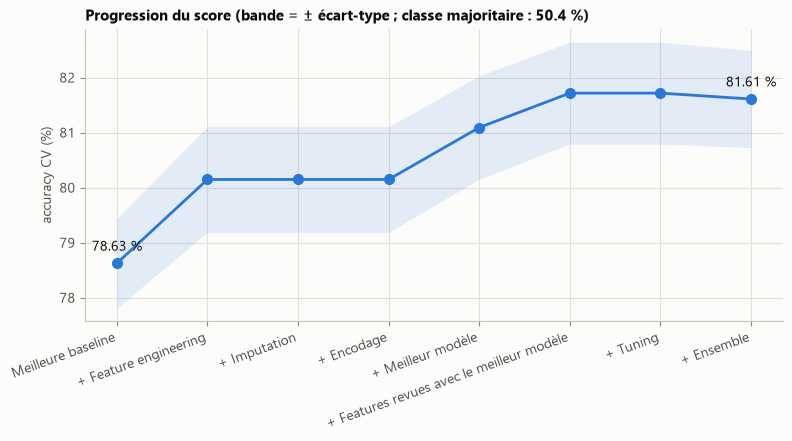

In [43]:
progress = pd.DataFrame({"Étape": [s for s, _ in PROGRESS], "Expérience retenue": [k.split(" · ", 1)[1] for _, k in PROGRESS],
                         "mean": [SCORES[k].mean() for _, k in PROGRESS], "std": [SCORES[k].std() for _, k in PROGRESS]})
progress["Accuracy CV"] = progress["mean"].map("{:.4f}".format) + " ± " + progress["std"].map("{:.4f}".format)
progress["Gain"] = progress["mean"].diff().map(lambda g: "–" if pd.isna(g) else f"{g:+.4f}")
display(progress[["Étape", "Expérience retenue", "Accuracy CV", "Gain"]])

steps = progress.iloc[1:]  # sans la classe majoritaire, qui écraserait l'échelle
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(steps["Étape"], steps["mean"] * 100, color=C_BLUE, marker="o", markersize=7)
ax.fill_between(steps["Étape"], (steps["mean"] - steps["std"]) * 100, (steps["mean"] + steps["std"]) * 100,
                color=C_BLUE, alpha=0.12, linewidth=0)
for idx in (0, len(steps) - 1):
    ax.annotate(f"{steps['mean'].iloc[idx] * 100:.2f} %", (idx, steps["mean"].iloc[idx] * 100), xytext=(0, 9),
                textcoords="offset points", ha="center", color=INK)
ax.set_ylabel("accuracy CV (%)")
ax.set_title(f"Progression du score (bande = ± écart-type ; classe majoritaire : {pct(progress['mean'].iloc[0], 1)})")
ax.tick_params(axis="x", labelrotation=20)
plt.setp(ax.get_xticklabels(), ha="right")
savefig(fig, "12_progression")

### Résumé chiffré

Les tableaux ci-dessous sont aussi écrits dans `results/summary.md` ; le journal complet des expériences est dans `results/experiments.csv`.

In [44]:
def md_table(df):
    """DataFrame -> tableau Markdown."""
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


minutes = (time.time() - T0) / 60
scaling_md = scaling_table.rename(columns=MODEL_LABELS).map("{:.4f}".format).rename_axis("Méthode").reset_index()
summary = "\n\n".join([
    "# Résumé des résultats",
    f"Score final (validation croisée 5×3) : **{mean_std(K_FINAL)}** — {K_FINAL.split(' · ', 1)[1]}",
    f"Validation par groupes : {mean_std(K_GROUP)}",
    f"Temps d'exécution du notebook : {minutes:.0f} min ({N_THREADS} cœurs logiques)",
    "## Progression du score", md_table(progress[["Étape", "Expérience retenue", "Accuracy CV", "Gain"]]),
    "## Comparaison des modèles", md_table(models_table),
    "## Effet de la normalisation", md_table(scaling_md),
    "## Effet de la PCA", md_table(pca_table.rename_axis("Configuration").reset_index()),
    "## Soumissions", md_table(submissions_table),
])
(RESULTS_DIR / "summary.md").write_text(summary + "\n", encoding="utf-8")

print(f"Score final : {mean_std(K_FINAL)}  ({K_FINAL.split(' · ', 1)[1]})")
print(f"Expériences enregistrées : {len(EXPERIMENTS)} -> {RESULTS_DIR / 'experiments.csv'}")
print(f"Temps d'exécution total : {minutes:.0f} min")

Score final : 0.8172 ± 0.0093  (CatBoost · + TotalSpend, NoSpend)
Expériences enregistrées : 114 -> results\experiments.csv
Temps d'exécution total : 49 min


<!--OBS:bilan-->

### Résultat final et fichier à soumettre

On compare la solution de la phase 10 et celle de la phase 11 (si elle a été exécutée) avec la règle de décision habituelle, puis on copie la soumission retenue dans `submissions/submission_finale.csv` et dans `submission.csv` (le fichier envoyé par le bouton *Submit* de Kaggle).

In [ ]:
import shutil

# Solutions candidates : (clé de l'expérience, fichier de soumission déjà écrit)
CANDIDATES = {"Phase 10": (K_FINAL, SUB_DIR / "submission_04_solution_finale.csv")}
if "K_P11" in globals():
    CANDIDATES["Phase 11"] = (K_P11, SUB_DIR / "submission_07_phase11.csv")

# La phase 11 n'est retenue que si elle passe la règle de décision habituelle
retenue = "Phase 10"
if "Phase 11" in CANDIDATES and compare(K_P11, K_FINAL)["adopted"]:
    retenue = "Phase 11"
k_retenue, fichier_retenu = CANDIDATES[retenue]

lignes = []
for phase, (k, f) in CANDIDATES.items():
    taux = pd.read_csv(f)["Transported"].mean()
    lignes.append({
        "Solution": phase + " - " + k.split(" · ", 1)[1],
        "Accuracy CV": mean_std(k),
        "Fichier": f.as_posix(),
        "% transportés": pct(taux, 1),
        "Retenue": "oui" if phase == retenue else "",
    })
display(pd.DataFrame(lignes))

if "Phase 11" in CANDIDATES:
    c = compare(K_P11, K_FINAL)
    print(f"Phase 11 vs phase 10 : gain {c['gain']:+.4f} ({c['wins']}/15 folds) -> {c['verdict']}")

# Fichier final : dans submissions/ et à la racine (Kaggle soumet submission.csv)
shutil.copy(fichier_retenu, SUB_DIR / "submission_finale.csv")
shutil.copy(fichier_retenu, "submission.csv")
print()
print(f"Solution retenue : {retenue} ({mean_std(k_retenue)})")
print("Fichiers écrits : submissions/submission_finale.csv et submission.csv")